In [1]:
# SCENARIO 02 - CENTRAL THERMAL / COOLING / WEATHER CONFIGURATION
from pathlib import Path
import os
import sys

_candidates = [Path.cwd().resolve(), Path.cwd().resolve()/'30days_scenario_02']
SCENARIO_ROOT = next((p for p in _candidates if (p/'bess_pipeline.py').is_file()), None)
if SCENARIO_ROOT is None:
    raise RuntimeError('Open this notebook from the copied 30days_scenario_02 folder.')
os.chdir(SCENARIO_ROOT)
if str(SCENARIO_ROOT) not in sys.path:
    sys.path.insert(0, str(SCENARIO_ROOT))
# Ensure local dependencies come from this isolated project even in a reused kernel.
for _module in ('bess_pipeline',):
    _loaded = sys.modules.get(_module)
    if _loaded is not None and not Path(_loaded.__file__).resolve().is_relative_to(SCENARIO_ROOT):
        del sys.modules[_module]
# Load the single local support module once; later cells keep its class identities.
import importlib as _scenario_importlib
import bess_pipeline as _bess_pipeline
_scenario_importlib.reload(_bess_pipeline)
from bess_pipeline import ThermalConfig, initialize_run, prepare_weather, plot_weather

# Public units are unchanged. bess_pipeline converts kJ -> J and kW -> W internally.
THERMAL_CONFIG = ThermalConfig(
    G=0.05,       # kg/s: coolant mass flow when cooling is ON
    Cp=4.180,     # kJ/(kg K): coolant specific heat; 4180 J/(kg K)
    Ts=25.0,      # degC: coolant inlet temperature
    Ton=32.0,     # degC: command ON at or above this battery temperature
    Toff=29.0,    # degC: command OFF at or below this battery temperature
    COP=2.0,      # thermal heat extracted / electrical energy input
    C=600.0,      # UNCHANGED: total battery thermal capacitance [kJ/K]
    r=2.0,        # UNCHANGED: battery-to-ambient thermal resistance [K/kW]
    r_bat=0.013,  # UNCHANGED: pack electrical resistance [ohm]
    V_nom=400.0,  # UNCHANGED: nominal pack voltage [V]
    step_seconds=900.0,  # confirmed 15-minute evaluation and hysteresis command period
    initial_temperature_c=None,  # inherit first ambient temperature, as in the original model
    initial_cooling_on=False,    # initial command is OFF; t=0 thresholds are evaluated normally
)
THERMAL_DURATION_HOURS = 720.0  # final electrical/Tamb sample held for the last half-hour
ASSESSMENT_INITIAL_SOH_PCT = 90.0  # unchanged original cycling-only assessment assumption
WEATHER_CONFIG = dict(
    seed=20261108, days=30, sample_hours=0.5, threshold_c=32.0,
    duration_tolerance_hours=1.0,  # +/- 1 h versus corresponding original odd/even reference day
)
RUN_FOLDER_NAME = 'scenario02_ef1b5703b8f6'  # fixed folder for imported and new results
RUN_ROOT = initialize_run(THERMAL_CONFIG, WEATHER_CONFIG, label='scenario02',
                          run_name=RUN_FOLDER_NAME)
print('Isolated run directory:', RUN_ROOT)
print('Thermal/control step: 900 s; electrical step remains 1800 s; analytical original heat balance.')


Isolated run directory: D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6
Thermal/control step: 900 s; electrical step remains 1800 s; analytical original heat balance.


In [2]:
# PMP FUNCTION DECLARATIONS - MODELS I, II, III, IV
# Copied verbatim from Energy_management.ipynb.
# This cell defines functions only. Set input arrays and operating parameters
# in later cells before calling the ODE/boundary functions.
# Original repeated interp_uniform declaration is preserved in Model III.

import numpy as np
from numba import njit

# ======================================================
# COMMON INTERPOLATION
# Source: Energy_management.ipynb, cell index 0
# ======================================================


@njit(fastmath=True)
def interp_uniform(t, values, dt):
    n = len(values)

    if t <= 0.0:
        return values[0]

    t_final = (n - 1) * dt

    if t >= t_final:
        return values[-1]

    i = int(t / dt)
    ratio = (t - i * dt) / dt

    return (
        values[i] * (1.0 - ratio)
        + values[i + 1] * ratio
    )



# ======================================================
# MODEL I
# Source: Energy_management.ipynb, cell index 1
# ======================================================


@njit(fastmath=True)
def penalty_termE_I(E, Emin, Emax, sigma=1e-2):
    x1 = Emin - E
    x2 = E - Emax

    a = 0.5 * (x1 + np.sqrt(x1**2 + sigma**2))
    b = 0.5 * (x2 + np.sqrt(x2**2 + sigma**2))

    Xdot_e = 0.5 * (a**2 + b**2)

    da_dE = -0.5 * (1.0 + x1 / np.sqrt(x1**2 + sigma**2))
    db_dE =  0.5 * (1.0 + x2 / np.sqrt(x2**2 + sigma**2))

    dXdot_e_dE = a * da_dE + b * db_dE

    return Xdot_e, dXdot_e_dE


@njit(fastmath=True)
def penalty_termP_I(Pb, Pbprev, lowbound, upbound, sigma=1e-2):
    """
    Model I does not use the resting-interval constraint.
    Function retained only so Models I–IV have identical structure.
    """
    return 0.0, 0.0


@njit(fastmath=True)
def dH_Pb_I(Pb, Pnet_t, lam_b, Pb_prev, psip, s1, z1, Pdg_rated):
    """
    dH/dPb = (s1 + z1)*Pb - z1*(Pnet - Pdg_rated) - lambda_b

    Pb_prev and psip are intentionally unused in Model I.
    """
    return (
        (s1 + z1) * Pb
        - z1 * (Pnet_t - Pdg_rated)
        - lam_b
    )


@njit(fastmath=True)
def odes_core_I(
    t, Eb, lam_b, psie, psip,
    t_grid, Pld_grid, Pb_prev_grid,
    dt, s1, z1,
    Pb_min, Pb_max,
    Pdg_min, Pdg_max, Pdg_rated,
    Eb_min, Eb_max
):
    n = len(t)
    dY = np.empty((4, n))

    for i in range(n):
        ti = t[i]
        Ebi = Eb[i]
        lambi = lam_b[i]

        Pnet_i = np.interp(
            ti,
            t_grid,
            Pld_grid
        )
    

        # Feasible BESS bounds from BESS and DG constraints:
        # Pdg = Pnet - Pb
        Pb_lower = max(
            Pb_min,
            Pnet_i - Pdg_max
        )

        Pb_upper = min(
            Pb_max,
            Pnet_i - Pdg_min
        )

        if Pb_lower > Pb_upper:
            Pb_lower = Pb_min
            Pb_upper = Pb_max

        # Closed-form solution of dH/dPb = 0
        Pb_unconstrained = (
            z1 * (Pnet_i - Pdg_rated)
            + lambi
        ) / (
            s1 + z1
        )

        # Apply physical bounds
        Pb_opt = min(
            max(Pb_unconstrained, Pb_lower),
            Pb_upper
        )

        # Energy-bound penalty
        Xdot_e, dXe_dE = penalty_termE_I(
            Ebi,
            Eb_min,
            Eb_max
        )

        # Model I has no resting constraint
        Xdot_p = 0.0

        dY[0, i] = -Pb_opt
        dY[1, i] = Xdot_e
        dY[2, i] = Xdot_p
        dY[3, i] = -psie * dXe_dE

    return dY


def odes_I(t, Y, psie, psip):
    Eb, _, _, lam_b = Y

    return odes_core_I(
        t, Eb, lam_b, psie, psip,
        t_grid, Pld_grid, Pb_prev_grid_I,
        dt, s1, z1,
        Pb_min, Pb_max,
        Pdg_min, Pdg_max, Pdg_rated,
        Eb_min, Eb_max
    )


def bc1_I(Y0, Yf, lam_init):
    return np.array([
        Yf[0] - Eb0,
        Y0[3] - lam_init,
        Y0[1],
        Y0[2]
    ])


def bc2_I(Y0, Yf, target_Eb0):
    return np.array([
        Y0[0] - target_Eb0,
        Yf[0] - Eb0,
        Y0[1],
        Y0[2]
    ])



# ======================================================
# MODEL II
# Source: Energy_management.ipynb, cell index 3
# ======================================================


@njit(fastmath=True)
def smooth_max_II(x, eps):
    return 0.5 * (
        x + np.sqrt(x * x + eps * eps)
    )


@njit(fastmath=True)
def penalty_termE_II(
    Eb,
    Eb_min,
    Eb_max
):

    upper = smooth_max_II(
        Eb - Eb_max,
        eps_energy_II
    )

    lower = smooth_max_II(
        Eb_min - Eb,
        eps_energy_II
    )

    Xdot_e = 0.5 * (
        upper * upper
        + lower * lower
    )

    dupper_dE = 0.5 * (
        1.0
        + (Eb - Eb_max)
        / np.sqrt(
            (Eb - Eb_max) ** 2
            + eps_energy_II ** 2
        )
    )

    dlower_dE = -0.5 * (
        1.0
        + (Eb_min - Eb)
        / np.sqrt(
            (Eb_min - Eb) ** 2
            + eps_energy_II ** 2
        )
    )

    dXe_dE = (
        upper * dupper_dE
        + lower * dlower_dE
    )

    return Xdot_e, dXe_dE


@njit(fastmath=True)
def resting_penalty_II(
    Pb,
    Pb_prev
):

    product = Pb * Pb_prev

    root_product = np.sqrt(
        product * product
        + gamma_II * gamma_II
    )

    # Fischer-Burmeister variable
    u = product - root_product

    # Smooth max(-u, 0)
    w = -u

    max_w = smooth_max_II(
        w,
        eps_max_II
    )

    # Xp_dot = 1/2 * max(-u, 0)^2
    Xdot_p = 0.5 * max_w * max_w

    # du/dPb
    du_dPb = Pb_prev * (
        1.0 - product / root_product
    )

    # d[max(-u, 0)]/dw
    dmaxw_dw = 0.5 * (
        1.0
        + w / np.sqrt(
            w * w
            + eps_max_II * eps_max_II
        )
    )

    dmaxw_dPb = (
        dmaxw_dw * (-du_dPb)
    )

    # dXp_dot/dPb
    dXp_dPb = max_w * dmaxw_dPb

    return Xdot_p, dXp_dPb


@njit(fastmath=True)
def dH_Pb_II(
    Pb,
    Pnet,
    lambda_b,
    Pb_prev,
    psi_p,
    s1,
    z1,
    Pdg_rated
):

    _, dXp_dPb = resting_penalty_II(
        Pb,
        Pb_prev
    )

    return (
        s1 * Pb
        - z1 * (
            Pnet
            - Pb
            - Pdg_rated
        )
        - lambda_b
        + psi_p * dXp_dPb
    )


@njit(fastmath=True)
def odes_core_II(
    t,
    Eb,
    lambda_b,
    psi_e,
    psi_p,
    t_grid,
    Pld_grid,
    Pb_prev_grid,
    dt,
    s1,
    z1,
    Pb_min,
    Pb_max,
    Pdg_min,
    Pdg_max,
    Pdg_rated,
    Eb_min,
    Eb_max
):

    n = len(t)
    dY = np.empty((4, n))

    for i in range(n):

        ti = t[i]
        Ebi = Eb[i]
        lambda_i = lambda_b[i]

        Pnet_i = np.interp(
            ti,
            t_grid,
            Pld_grid
        )

        t_prev = max(
            0.0,
            ti - dt
        )

        Pb_prev_i = np.interp(
            t_prev,
            t_grid,
            Pb_prev_grid
        )

        # Pdg = Pnet - Pb
        Pb_lower = max(
            Pb_min,
            Pnet_i - Pdg_max
        )

        Pb_upper = min(
            Pb_max,
            Pnet_i - Pdg_min
        )

        if Pb_lower > Pb_upper:
            Pb_lower = Pb_min
            Pb_upper = Pb_max

        # Bisection for dH/dPb = 0
        a = Pb_lower
        b = Pb_upper

        fa = dH_Pb_II(
            a,
            Pnet_i,
            lambda_i,
            Pb_prev_i,
            psi_p,
            s1,
            z1,
            Pdg_rated
        )

        fb = dH_Pb_II(
            b,
            Pnet_i,
            lambda_i,
            Pb_prev_i,
            psi_p,
            s1,
            z1,
            Pdg_rated
        )

        if fa * fb > 0.0:

            if abs(fa) < abs(fb):
                Pb_opt = a
            else:
                Pb_opt = b

        else:

            Pb_opt = 0.5 * (a + b)

            for _ in range(50):

                Pb_opt = 0.5 * (a + b)

                fc = dH_Pb_II(
                    Pb_opt,
                    Pnet_i,
                    lambda_i,
                    Pb_prev_i,
                    psi_p,
                    s1,
                    z1,
                    Pdg_rated
                )

                if abs(fc) < 1e-8:
                    break

                if fa * fc < 0.0:
                    b = Pb_opt
                    fb = fc
                else:
                    a = Pb_opt
                    fa = fc

        Xdot_e, dXe_dE = penalty_termE_II(
            Ebi,
            Eb_min,
            Eb_max
        )

        Xdot_p, _ = resting_penalty_II(
            Pb_opt,
            Pb_prev_i
        )

        dY[0, i] = -Pb_opt
        dY[1, i] = Xdot_e
        dY[2, i] = Xdot_p
        dY[3, i] = -psi_e * dXe_dE

    return dY


def odes_II(
    t,
    y,
    psi_e,
    psi_p
):

    return odes_core_II(
        t,
        y[0],
        y[3],
        psi_e,
        psi_p,
        t_grid,
        Pld_grid,
        Pb_prev_grid_II,
        dt,
        s1,
        z1,
        Pb_min,
        Pb_max,
        Pdg_min,
        Pdg_max,
        Pdg_rated,
        Eb_min,
        Eb_max
    )


def bc1_II(
    y0,
    yf,
    lambda_init
):

    return np.array([
        yf[0] - Eb0,
        y0[3] - lambda_init,
        y0[1],
        y0[2]
    ])


def bc2_II(
    y0,
    yf,
    target_Eb0
):

    return np.array([
        y0[0] - target_Eb0,
        yf[0] - Eb0,
        y0[1],
        y0[2]
    ])



# ======================================================
# MODEL III
# Source: Energy_management.ipynb, cell index 5
# ======================================================


@njit(fastmath=True)
def alpha_temperature_III(
    T_amb_value,
    T_high,
    T_max,
    temperature_weight
):
    """
    When temperature_weight = 1:

    alpha_T = T_amb / T_max, if T_amb >= T_high
            = 0,             if T_amb < T_high
    """
    if T_amb_value >= T_high:
        return (
            temperature_weight
            * T_amb_value
            / T_max
        )

    return 0.0


@njit(fastmath=True)
def penalty_termE_III(E, Emin, Emax, sigma=1e-2):
    x1 = Emin - E
    x2 = E - Emax

    a = 0.5 * (
        x1 + np.sqrt(x1**2 + sigma**2)
    )

    b = 0.5 * (
        x2 + np.sqrt(x2**2 + sigma**2)
    )

    Xdot_e = 0.5 * (a**2 + b**2)

    da_dE = -0.5 * (
        1.0 + x1 / np.sqrt(x1**2 + sigma**2)
    )

    db_dE = 0.5 * (
        1.0 + x2 / np.sqrt(x2**2 + sigma**2)
    )

    dXdot_e_dE = a * da_dE + b * db_dE

    return Xdot_e, dXdot_e_dE


@njit(fastmath=True)
def penalty_termP_III(Pb, Pbprev):
    """
    Model III has no resting-interval constraint.
    Retained only for a common Model I–IV structure.
    """
    return 0.0, 0.0


@njit(fastmath=True)
def dH_Pb_III(
    Pb,
    Pnet_t,
    T_amb_t,
    lam_b,
    Pb_prev,
    psip,
    s1,
    z1,
    Pdg_rated,
    T_high,
    T_max,
    temperature_weight
):
    alpha_T = alpha_temperature_III(
        T_amb_t,
        T_high,
        T_max,
        temperature_weight
    )

    return (
        (s1 + alpha_T + z1) * Pb
        - z1 * (Pnet_t - Pdg_rated)
        - lam_b
    )


@njit(fastmath=True)
def odes_core_III(
    t,
    Eb,
    lam_b,
    psie,
    psip,
    t_grid,
    Pld_grid,
    T_amb,
    Pb_prev_grid,
    dt,
    s1,
    z1,
    Pb_min,
    Pb_max,
    Pdg_min,
    Pdg_max,
    Pdg_rated,
    Eb_min,
    Eb_max,
    T_high,
    T_max,
    temperature_weight
):
    n = len(t)
    dY = np.empty((4, n))

    for i in range(n):
        ti = t[i]
        Ebi = Eb[i]
        lambi = lam_b[i]

        Pnet_i = np.interp(
            ti,
            t_grid,
            Pld_grid
        )

        T_amb_i = np.interp(
            ti,
            t_grid,
            T_amb
        )

        # Feasible BESS bounds from BESS and DG constraints
        # Pdg = Pnet - Pb
        Pb_lower = max(
            Pb_min,
            Pnet_i - Pdg_max
        )

        Pb_upper = min(
            Pb_max,
            Pnet_i - Pdg_min
        )

        if Pb_lower > Pb_upper:
            Pb_lower = Pb_min
            Pb_upper = Pb_max

        # Temperature coefficient
        alpha_T = alpha_temperature_III(
            T_amb_i,
            T_high,
            T_max,
            temperature_weight
        )

        # Closed-form solution of dH/dPb = 0
        Pb_unconstrained = (
            z1 * (Pnet_i - Pdg_rated)
            + lambi
        ) / (
            s1 + alpha_T + z1
        )

        # Apply feasible BESS / DG limits
        Pb_opt = min(
            max(Pb_unconstrained, Pb_lower),
            Pb_upper
        )

        # Energy-bound penalty
        Xdot_e, dXe_dE = penalty_termE_III(
            Ebi,
            Eb_min,
            Eb_max
        )

        # Model III has no resting constraint
        Xdot_p = 0.0

        dY[0, i] = -Pb_opt
        dY[1, i] = Xdot_e
        dY[2, i] = Xdot_p
        dY[3, i] = -psie * dXe_dE

    return dY


def odes_III(t, Y, psie, psip):
    Eb, _, _, lam_b = Y

    return odes_core_III(
        t,
        Eb,
        lam_b,
        psie,
        psip,
        t_grid,
        Pld_grid,
        T_amb,
        Pb_prev_grid_III,
        dt,
        s1,
        z1,
        Pb_min,
        Pb_max,
        Pdg_min,
        Pdg_max,
        Pdg_rated,
        Eb_min,
        Eb_max,
        T_high,
        T_max,
        temperature_weight_III
    )


def bc1_III(Y0, Yf, lam_init):
    return np.array([
        Yf[0] - Eb0,
        Y0[3] - lam_init,
        Y0[1],
        Y0[2]
    ])


def bc2_III(Y0, Yf, target_Eb0):
    return np.array([
        Y0[0] - target_Eb0,
        Yf[0] - Eb0,
        Y0[1],
        Y0[2]
    ])


@njit(fastmath=True)
def interp_uniform(t, values, dt):
    n = len(values)

    if t <= 0.0:
        return values[0]

    t_final = (n - 1) * dt

    if t >= t_final:
        return values[-1]

    i = int(t / dt)
    ratio = (t - i * dt) / dt

    return (
        values[i] * (1.0 - ratio)
        + values[i + 1] * ratio
    )



# ======================================================
# MODEL IV
# Source: Energy_management.ipynb, cell index 7
# ======================================================


@njit(fastmath=True)
def smooth_max_IV(x, eps):
    return 0.5 * (x + np.sqrt(x * x + eps * eps))


@njit(fastmath=True)
def alpha_temperature_IV(
    Tamb,
    T_high,
    T_max,
    temperature_weight
):
    if Tamb >= T_high:
        return temperature_weight * Tamb / T_max

    return 0.0


@njit(fastmath=True)
def penalty_termE_IV(Eb, Eb_min, Eb_max):

    upper = smooth_max_IV(
        Eb - Eb_max,
        eps_energy_IV
    )

    lower = smooth_max_IV(
        Eb_min - Eb,
        eps_energy_IV
    )

    Xdot_e = 0.5 * (
        upper * upper
        + lower * lower
    )

    dupper_dE = 0.5 * (
        1.0
        + (Eb - Eb_max)
        / np.sqrt(
            (Eb - Eb_max) ** 2
            + eps_energy_IV ** 2
        )
    )

    dlower_dE = -0.5 * (
        1.0
        + (Eb_min - Eb)
        / np.sqrt(
            (Eb_min - Eb) ** 2
            + eps_energy_IV ** 2
        )
    )

    dXe_dE = (
        upper * dupper_dE
        + lower * dlower_dE
    )

    return Xdot_e, dXe_dE


@njit(fastmath=True)
def resting_penalty_IV(Pb, Pb_prev):

    product = Pb * Pb_prev

    root_product = np.sqrt(
        product * product
        + gamma_IV * gamma_IV
    )

    # Fischer-Burmeister variable
    u = product - root_product

    # smooth max(-u, 0)
    w = -u

    max_w = smooth_max_IV(
        w,
        eps_max_IV
    )

    # Xp_dot = 1/2 * max(-u, 0)^2
    Xdot_p = 0.5 * max_w * max_w

    # du / dPb
    du_dPb = Pb_prev * (
        1.0 - product / root_product
    )

    # d[max(-u, 0)] / dw
    dmaxw_dw = 0.5 * (
        1.0
        + w / np.sqrt(
            w * w
            + eps_max_IV * eps_max_IV
        )
    )

    dmaxw_dPb = dmaxw_dw * (-du_dPb)

    # dXp_dot / dPb
    dXp_dPb = max_w * dmaxw_dPb

    return Xdot_p, dXp_dPb


@njit(fastmath=True)
def dH_Pb_IV(
    Pb,
    Pnet,
    Tamb,
    lambda_b,
    Pb_prev,
    psi_p,
    s1,
    z1,
    Pdg_rated,
    T_high,
    T_max,
    temperature_weight
):
    alpha_T = alpha_temperature_IV(
        Tamb,
        T_high,
        T_max,
        temperature_weight
    )

    _, dXp_dPb = resting_penalty_IV(
        Pb,
        Pb_prev
    )

    return (
        (s1 + alpha_T) * Pb
        - z1 * (Pnet - Pb - Pdg_rated)
        - lambda_b
        + psi_p * dXp_dPb
    )


@njit(fastmath=True)
def odes_core_IV(
    t,
    Eb,
    lambda_b,
    psi_e,
    psi_p,
    t_grid,
    Pld_grid,
    T_amb,
    Pb_prev_grid,
    dt,
    s1,
    z1,
    Pb_min,
    Pb_max,
    Pdg_min,
    Pdg_max,
    Pdg_rated,
    Eb_min,
    Eb_max,
    T_high,
    T_max,
    temperature_weight
):
    n = len(t)
    dY = np.empty((4, n))

    for i in range(n):

        ti = t[i]
        Ebi = Eb[i]
        lambda_i = lambda_b[i]

        Pnet_i = np.interp(
            ti,
            t_grid,
            Pld_grid
        )

        Tamb_i = np.interp(
            ti,
            t_grid,
            T_amb
        )

        t_prev = max(0.0, ti - dt)

        Pb_prev_i = np.interp(
            t_prev,
            t_grid,
            Pb_prev_grid
        )

        # Pdg = Pnet - Pb
        Pb_lower = max(
            Pb_min,
            Pnet_i - Pdg_max
        )

        Pb_upper = min(
            Pb_max,
            Pnet_i - Pdg_min
        )

        if Pb_lower > Pb_upper:
            Pb_lower = Pb_min
            Pb_upper = Pb_max

        # Bisection for dH/dPb = 0
        a = Pb_lower
        b = Pb_upper

        fa = dH_Pb_IV(
            a,
            Pnet_i,
            Tamb_i,
            lambda_i,
            Pb_prev_i,
            psi_p,
            s1,
            z1,
            Pdg_rated,
            T_high,
            T_max,
            temperature_weight
        )

        fb = dH_Pb_IV(
            b,
            Pnet_i,
            Tamb_i,
            lambda_i,
            Pb_prev_i,
            psi_p,
            s1,
            z1,
            Pdg_rated,
            T_high,
            T_max,
            temperature_weight
        )

        if fa * fb > 0.0:

            if abs(fa) < abs(fb):
                Pb_opt = a
            else:
                Pb_opt = b

        else:
            Pb_opt = 0.5 * (a + b)

            for _ in range(50):

                Pb_opt = 0.5 * (a + b)

                fc = dH_Pb_IV(
                    Pb_opt,
                    Pnet_i,
                    Tamb_i,
                    lambda_i,
                    Pb_prev_i,
                    psi_p,
                    s1,
                    z1,
                    Pdg_rated,
                    T_high,
                    T_max,
                    temperature_weight
                )

                if abs(fc) < 1e-8:
                    break

                if fa * fc < 0.0:
                    b = Pb_opt
                    fb = fc
                else:
                    a = Pb_opt
                    fa = fc

        Xdot_e, dXe_dE = penalty_termE_IV(
            Ebi,
            Eb_min,
            Eb_max
        )

        Xdot_p, _ = resting_penalty_IV(
            Pb_opt,
            Pb_prev_i
        )

        dY[0, i] = -Pb_opt
        dY[1, i] = Xdot_e
        dY[2, i] = Xdot_p
        dY[3, i] = -psi_e * dXe_dE

    return dY


def odes_IV(
    t,
    y,
    psi_e,
    psi_p,
    temperature_weight
):
    return odes_core_IV(
        t,
        y[0],
        y[3],
        psi_e,
        psi_p,
        t_grid,
        Pld_grid,
        T_amb,
        Pb_prev_grid_IV,
        dt,
        s1,
        z1,
        Pb_min,
        Pb_max,
        Pdg_min,
        Pdg_max,
        Pdg_rated,
        Eb_min,
        Eb_max,
        T_high_IV,
        T_max_IV,
        temperature_weight
    )


def bc1_IV(y0, yf, lambda_init):
    return np.array([
        yf[0] - Eb0,
        y0[3] - lambda_init,
        y0[1],
        y0[2]
    ])


def bc2_IV(y0, yf, target_Eb0):
    return np.array([
        y0[0] - target_Eb0,
        yf[0] - Eb0,
        y0[1],
        y0[2]
    ])


1440
Successfully connected to folder: 8.2022
1440
30 daily files: 01/08/2022 to 30/08/2022; 1440 nodes, dt=0.5 h, BVP horizon 0..719.5 h.
Ambient scenario: 30 unique days; odd/even original reference duration +/- 1 h.


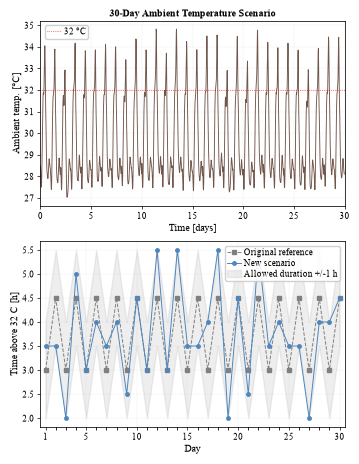

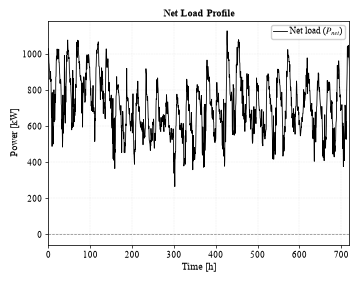

In [3]:
import numpy as np
from scipy.integrate import solve_bvp
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import pandas as pd
import os
import glob
from numba import njit
from pathlib import Path
from datetime import datetime, timedelta
from IPython.display import display

# ======================================================
# 1. DATA LOADING & PRE-PROCESSING
# ======================================================

# Parameters
eta_pv, eta_b, eta_dg = 0.985, 1.0, 1.0
s1, z1, dt = 0.3, 0.7, 0.5
Pb_max, Pb_min = 500, -500
Eb_max, Eb_min = 2000 * 0.95, 2000 * 0.05
Eb0 = 0.4 * Eb_max

Pdg_min = 0.0
Pdg_max = 1000.0
Pdg_rated = 0.8 * Pdg_max

file_start, file_end = 0, 30
RUN_DAYS_30DAYS = 30
OUTPUT_DIR_30DAYS = RUN_ROOT / '30days_results'
MODELS_TO_RUN_30DAYS = ('I', 'II', 'III', 'IV')

Pv, P_seft, Pld_list = [], [], []

# Thirty distinct days, each bounded by its corresponding original reference day.
# Use the module loaded in cell 1 without recreating its parameter classes.
from bess_pipeline import prepare_weather
scenario_weather, scenario_weather_daily = prepare_weather(RUN_ROOT, WEATHER_CONFIG)
T_amb = scenario_weather.Tamb_degC.to_numpy(dtype=float)
print(len(T_amb))
T_amb_np = np.array(T_amb)


found_folders = glob.glob("8.2022*")


if not found_folders:
    dirs = [d for d in os.listdir(".") if os.path.isdir(d)]
    print(f"I couldn't find the folder. Here is what I see: {dirs}")
    raise FileNotFoundError("Check the folder name spelling or encoding.")

folder_path = found_folders[0]
print(f"Successfully connected to folder: {folder_path}")

files = [
    f for f in glob.glob(os.path.join(folder_path, "*.xls*"))
    if not os.path.basename(f).startswith("~$")
]

# Sort daily files chronologically before selecting 30 consecutive days.
files.sort(key=lambda name: datetime.strptime(Path(name).stem, '%d.%m.%Y'))

if not files:
    raise FileNotFoundError(f"Folder '{folder_path}' contains no Excel files.")

Pv, P_seft, Pld_list = [], [], []

if (not np.isfinite(dt) or dt <= 0 or file_end-file_start != RUN_DAYS_30DAYS
        or file_start < 0 or file_end > len(files)):
    raise ValueError('Select exactly 30 available daily files and use a positive time step.')
samples_per_day_30days = int(round(24.0/dt))
if not np.isclose(samples_per_day_30days*dt, 24.0):
    raise ValueError('dt must divide one day into an integer number of samples.')
selected_files_30days = files[file_start:file_end]
selected_dates_30days = [datetime.strptime(Path(name).stem, '%d.%m.%Y')
                        for name in selected_files_30days]
if any(right-left != timedelta(days=1)
       for left,right in zip(selected_dates_30days[:-1], selected_dates_30days[1:])):
    raise ValueError('Selected input files must represent 30 consecutive calendar days.')

for daily_file_30days in selected_files_30days:
    df_raw = pd.read_excel(daily_file_30days, sheet_name=0, header=None)
    # Keep the three signals aligned: remove only rows where all three are blank.
    daily_data_30days = df_raw.iloc[10:, [24,27,30]].dropna(how='all')
    daily_data_30days = daily_data_30days.apply(pd.to_numeric, errors='raise')
    if (len(daily_data_30days) != samples_per_day_30days
            or not np.isfinite(daily_data_30days.to_numpy(dtype=float)).all()):
        raise ValueError(f'{daily_file_30days}: expected {samples_per_day_30days} complete synchronized samples.')
    Pv.append(daily_data_30days.iloc[:,0].to_numpy(dtype=float))
    P_seft.append(daily_data_30days.iloc[:,1].to_numpy(dtype=float))
    Pld_list.append(daily_data_30days.iloc[:,2].to_numpy(dtype=float))

Pv = np.concatenate(Pv)
Pld = np.concatenate(Pld_list) * 3  
P_seft = np.concatenate(P_seft)

if not (len(Pv) == len(Pld) == len(P_seft)):
    raise ValueError(
        f"Unequal data lengths: PV={len(Pv)}, load={len(Pld)}, "
        f"self-consumption={len(P_seft)}"
    )

Pld_net = Pld - eta_pv * Pv - P_seft
print(len(Pld_net))
N = len(Pld_net)
t_grid = np.arange(N) * dt
Pld_grid = Pld_net.copy()

# ======================================================
# MODEL/SOLVER PARAMETERS - edit here, then rerun cells 1 -> 2 -> 3.
# The original ODEs, stationarity and boundary functions in cell 1 are unchanged.
# ======================================================
if N != RUN_DAYS_30DAYS*samples_per_day_30days or len(T_amb) != N:
    raise ValueError(f'Need {RUN_DAYS_30DAYS*samples_per_day_30days} load and ambient samples; got {N} and {len(T_amb)}.')
if not np.isfinite(np.column_stack([Pld, Pv, P_seft, Pld_net, T_amb])).all():
    raise ValueError('Load, generation and ambient inputs must be finite.')
if not np.isclose(s1+z1, 1.0) or min(s1,z1) < 0:
    raise ValueError('Require nonnegative s1/z1 with s1+z1=1.')

# Values match the four original Energy_management model cells.
BVP_TOL_I = BVP_TOL_II = BVP_TOL_III = BVP_TOL_IV = 1e-3
BVP_MAX_NODES_I = BVP_MAX_NODES_II = BVP_MAX_NODES_IV = 30000
BVP_MAX_NODES_III = 10000  # Match the Model III solver in Energy_management.ipynb.
BC_REPORT_TOL_30DAYS = 1e-3  # Reporting only; does not change the original loop stop criteria.

# Model I: energy penalty only.
psi_e_I, psi_p_I = 0.2, 0.0
eps_limit_e_I = 0.5
max_outer_iter_I = 5000
bc_homotopy_steps_I = 3
penalty_growth_e_I = 1.01
lambda_init_I = 0.0
Pb_prev_grid_I = np.full(N, 10.0)
Y_guess_I = np.zeros((4,N))
Y_guess_I[0,:], Y_guess_I[3,:] = Eb0, lambda_init_I

# Model II: resting penalty, same smoothness and cold-start configuration.
gamma_II, eps_max_II, eps_energy_II = 1e-3, 1e-3, 1e-3
psi_e_II, psi_p_II = 1, 0.5
eps_limit_e_II, eps_limit_p_II = 0.5, 0.5
max_outer_iter_II = 5000
bc_homotopy_steps_II = 5
penalty_growth_e_II, penalty_growth_p_II = 1.03, 1.01
lambda_init_II = 0.0
Pb_prev_grid_II = np.zeros(N)
Y_guess_II = np.zeros((4,N))
Y_guess_II[0,:], Y_guess_II[3,:] = Eb0, lambda_init_II

# Model III: gradual ambient-temperature penalty.
T_high, T_max = 32.0, float(np.max(T_amb))
psi_e_III, psi_p_III = 1.0, 0.0
eps_limit_e_III = 0.5
max_outer_iter_III = 5000
bc_homotopy_steps_III = 3
penalty_growth_e_III = 1.2
temperature_steps_III, temperature_weight_III = 3, 0.0
lambda_init_III = 0.0
Pb_prev_grid_III = np.zeros(N)
Y_guess_III = np.zeros((4,N))
Y_guess_III[0,:], Y_guess_III[3,:] = Eb0, lambda_init_III

# Model IV: resting and ambient-temperature penalties.
gamma_IV, eps_max_IV, eps_energy_IV = 1e-3, 1e-3, 1e-3
T_high_IV, T_max_IV = 32.0, float(np.max(T_amb))
psi_e_IV, psi_p_IV = 1, 0.3
eps_limit_e_IV, eps_limit_p_IV = 0.5, 0.5
max_outer_iter_IV = 5000
bc_homotopy_steps_IV = 3
temperature_steps_IV, temperature_weight_IV = 3, 0.0
penalty_growth_e_IV, penalty_growth_p_IV = 1.05, 1.03
lambda_init_IV = 0.0
Pb_prev_grid_IV = np.zeros(N)
Y_guess_IV = np.zeros((4,N))
Y_guess_IV[0,:], Y_guess_IV[3,:] = Eb0, lambda_init_IV

for _model_30days in ('I','II','III','IV'):
    if (globals()[f'BVP_MAX_NODES_{_model_30days}'] < N
            or globals()[f'BVP_TOL_{_model_30days}'] <= 0
            or globals()[f'max_outer_iter_{_model_30days}'] < 1
            or globals()[f'bc_homotopy_steps_{_model_30days}'] < 1):
        raise ValueError(f'Model {_model_30days}: invalid mesh, tolerance or iteration configuration.')
if min(temperature_steps_III,temperature_steps_IV) < 1:
    raise ValueError('Temperature continuation needs at least one step.')
if not MODELS_TO_RUN_30DAYS or not set(MODELS_TO_RUN_30DAYS).issubset({'I','II','III','IV'}):
    raise ValueError('MODELS_TO_RUN_30DAYS must select I, II, III and/or IV.')

# Snapshots preserve a cold start when rerunning cell 3 after a previous solve.
INITIAL_SOLVER_STATE_30DAYS = {
    model: {'psi_e': globals()[f'psi_e_{model}'], 'psi_p': globals()[f'psi_p_{model}'],
            'Pb_prev': globals()[f'Pb_prev_grid_{model}'].copy(),
            'Y_guess': globals()[f'Y_guess_{model}'].copy()}
    for model in ('I','II','III','IV')
}
print(f'30 daily files: {selected_dates_30days[0]:%d/%m/%Y} to {selected_dates_30days[-1]:%d/%m/%Y}; '
      f'{N} nodes, dt={dt:g} h, BVP horizon {t_grid[0]:g}..{t_grid[-1]:g} h.')
print('Ambient scenario: 30 unique days; odd/even original reference duration +/- 1 h.')
plot_weather(scenario_weather, scenario_weather_daily, RUN_ROOT/'inputs')


# Plot net load (presentation only; input arrays are unchanged).
from bess_pipeline import IEEE_RC, column_size
with plt.rc_context(IEEE_RC):
    plt.figure(figsize=column_size(2.1))
    plt.plot(t_grid, Pld_net, color='black', linewidth=.6, label=r'Net load ($P_{net}$)')
    plt.axhline(0, color='gray', linestyle='--', linewidth=.5)
    plt.title('Net Load Profile')
    plt.xlabel('Time [h]')
    plt.ylabel('Power [kW]')
    plt.xlim(t_grid[0], t_grid[-1])
    plt.grid(True, linestyle='--', linewidth=.35, alpha=.25)
    plt.legend()
    plt.tight_layout(pad=.5)
    plt.show()

@njit(fastmath=True)
def interp_uniform(t, values, dt):
    n = len(values)

    if t <= 0.0:
        return values[0]

    t_final = (n - 1) * dt

    if t >= t_final:
        return values[-1]

    i = int(t / dt)
    ratio = (t - i * dt) / dt

    return (
        values[i] * (1.0 - ratio)
        + values[i + 1] * ratio
    )

In [4]:
# SOLVE THE CONTINUOUS 30-DAY PMP HORIZON - MODELS I, II, III, IV
# Run cells 1 and 2 first. No daily reset and no rolling horizon.
# The original per-model bc1 -> bc2 homotopy, penalty updates and stop rules are retained.
# Only paths and solver settings have been parameterized; no PMP functions are redefined.
from time import perf_counter as _perf_counter_30days

# Always resume from this exact folder, including when only cell 4 is rerun.
RUN_ROOT = (SCENARIO_ROOT / 'runs' / 'scenario02_ef1b5703b8f6').resolve()
RUN_ROOT.mkdir(parents=True, exist_ok=True)
for _run_subfolder_30days in ('inputs', '30days_results', 'validation'):
    (RUN_ROOT / _run_subfolder_30days).mkdir(exist_ok=True)
OUTPUT_DIR_30DAYS = RUN_ROOT / '30days_results'
_expected_excel_30days = [
    OUTPUT_DIR_30DAYS / f'Model_{_model}_results_30days.xlsx'
    for _model in ('I', 'II', 'III', 'IV')
]
if all(_path.is_file() for _path in _expected_excel_30days):
    print(f'All four model Excel results already exist in {OUTPUT_DIR_30DAYS}; skipping PMP solves.')
else:
    print('Missing model results:', ', '.join(
        _path.name for _path in _expected_excel_30days if not _path.is_file()))
    print('Only models without Excel results will be solved.')

_required_30days = ['INITIAL_SOLVER_STATE_30DAYS','N','t_grid','Pld_grid','Pld_net',
                   'T_amb','OUTPUT_DIR_30DAYS','MODELS_TO_RUN_30DAYS']
_required_30days += [f'{prefix}_{m}' for m in ('I','II','III','IV')
                    for prefix in ('odes','bc1','bc2')]
_missing_30days = [name for name in _required_30days if name not in globals()]
if _missing_30days:
    raise RuntimeError('Run cells 1 and 2 first. Missing: '+', '.join(_missing_30days))
if any(np.asarray(values).shape != (N,) for values in (t_grid,Pld_grid,Pld_net,T_amb)):
    raise ValueError('Data length changed; rerun cell 2 before solving.')
OUTPUT_DIR_30DAYS.mkdir(parents=True,exist_ok=True)
report_rows_30days = []
model_results_30days = {}
solutions_30days = {}
report_path_30days = OUTPUT_DIR_30DAYS / 'Solver_report_30days.xlsx'


# Resume rule: an existing model Excel file counts as completed for skipping PMP.
import hashlib as _hashlib_30days
import json as _json_30days
from types import CodeType as _CodeType_30days

def _code_fingerprint_30days(code):
    # Exclude execution filename/line numbers, which change after a kernel restart.
    return {'bytecode':code.co_code.hex(), 'names':code.co_names, 'varnames':code.co_varnames,
            'argcount':code.co_argcount, 'kwonlyargcount':code.co_kwonlyargcount,
            'constants':[_code_fingerprint_30days(c) if isinstance(c,_CodeType_30days)
                         else repr(c) for c in code.co_consts]}

def _run_signature_30days(model):
    common=['dt','s1','z1','eta_pv','eta_b','eta_dg','Pb_min','Pb_max','Pdg_min',
            'Pdg_max','Pdg_rated','Eb_min','Eb_max','Eb0','BC_REPORT_TOL_30DAYS']
    specific=[f'{prefix}_{model}' for prefix in
              ['BVP_TOL','BVP_MAX_NODES','max_outer_iter','bc_homotopy_steps',
               'eps_limit_e','lambda_init','penalty_growth_e']]
    if model in ('II','IV'):
        specific += [f'{prefix}_{model}' for prefix in
                     ['gamma','eps_max','eps_energy','eps_limit_p','penalty_growth_p']]
    if model=='III': specific += ['T_high','T_max','temperature_steps_III']
    if model=='IV': specific += ['T_high_IV','T_max_IV','temperature_steps_IV']
    params={name:float(globals()[name]) for name in common+specific}
    params.update({f'initial_{key}':float(INITIAL_SOLVER_STATE_30DAYS[model][key])
                   for key in ['psi_e','psi_p']})
    functions={}
    for name,value in list(globals().items()):
        if name=='interp_uniform' or name.endswith('_'+model):
            function=getattr(value,'py_func',value)
            if hasattr(function,'__code__'):
                functions[name]=_code_fingerprint_30days(function.__code__)
    digest=_hashlib_30days.sha256(_json_30days.dumps(
        {'version':1,'model':model,'params':params,'functions':functions},sort_keys=True).encode('utf-8'))
    for values in [t_grid,Pld_grid,Pld_net,Pld,Pv,P_seft,T_amb,
                   INITIAL_SOLVER_STATE_30DAYS[model]['Pb_prev'],
                   INITIAL_SOLVER_STATE_30DAYS[model]['Y_guess']]:
        array=np.ascontiguousarray(values,dtype='<f8')
        digest.update(str(array.shape).encode('ascii'))
        digest.update(array.tobytes())
    return digest.hexdigest()

def _result_paths_30days(model):
    result=OUTPUT_DIR_30DAYS / f'Model_{model}_results_30days.xlsx'
    checkpoint=OUTPUT_DIR_30DAYS / f'Model_{model}_checkpoint.json'
    return result,checkpoint

def _write_report_30days(row):
    global solver_report_30days
    _report_by_model_30days[row['Model']]=dict(row)
    solver_report_30days=pd.DataFrame([
        _report_by_model_30days[m] for m in ('I','II','III','IV') if m in _report_by_model_30days])
    temporary=report_path_30days.with_name('Solver_report_30days.pending.xlsx')
    solver_report_30days.to_excel(temporary,index=False)
    temporary.replace(report_path_30days)

def _validated_cached_frame_30days(model,result):
    frame=pd.read_excel(result)
    aliases={
        'time':('time_hour','Time_hour'), 'net':('P_net_kW','Pnet_kW'),
        'power':('P_battery_kW','Pb_kW'), 'diesel':('P_diesel_kW','Pdg_kW'),
        'energy':('E_battery_kWh','Eb_kWh'), 'xe':('X_energy_penalty','Xe'),
        'xp':('X_resting_penalty','Xp'), 'lambda':('lambda_b',),
    }
    values={}
    for key,candidates in aliases.items():
        column=next((c for c in candidates if c in frame),None)
        if column is None: raise ValueError(f'missing {key} column')
        values[key]=frame[column].to_numpy(dtype=float)
    if len(frame)!=N or not all(np.isfinite(v).all() for v in values.values()):
        raise ValueError('wrong length or non-finite result')
    if not np.allclose(values['time'],t_grid,rtol=0,atol=1e-6):
        raise ValueError('time grid changed')
    if not np.allclose(values['net'],Pld_grid,rtol=0,atol=1e-6):
        raise ValueError('net load changed')
    if not np.allclose(values['energy'][[0,-1]],Eb0,rtol=0,atol=BC_REPORT_TOL_30DAYS):
        raise ValueError('energy boundary conditions differ')
    violation=np.max(np.maximum(values['energy']-Eb_max,0)+np.maximum(Eb_min-values['energy'],0))
    if violation>=globals()[f'eps_limit_e_{model}']:
        raise ValueError('energy constraint no longer meets the configured tolerance')
    for column,expected in [('P_load_kW',Pld),('P_pv_kW',Pv*eta_pv),
                            ('P_self_consumption_kW',P_seft),('Tamb_degC',T_amb),
                            ('ambient_temperature_degC',T_amb)]:
        if column in frame and not np.allclose(frame[column],expected,rtol=0,atol=1e-6):
            raise ValueError(f'{column} changed')
    return frame,values

def _commit_checkpoint_30days(model,row):
    result,checkpoint=_result_paths_30days(model)
    if row['Status']!='SUCCESS': return
    _validated_cached_frame_30days(model,result)
    record={'version':1,'signature':_signatures_30days[model],
            'result_sha256':_hashlib_30days.sha256(result.read_bytes()).hexdigest(),
            'report':row}
    temporary=checkpoint.with_suffix('.pending.json')
    temporary.write_text(_json_30days.dumps(record,indent=2,default=lambda v:v.item()),encoding='utf-8')
    temporary.replace(checkpoint)

def _load_completed_30days(model):
    # Existing model Excel is sufficient to skip solving, even without a checkpoint.
    # Retain original convergence labels; file availability does not certify SUCCESS.
    result, _ = _result_paths_30days(model)
    if not result.is_file():
        return False

    # Read errors stop the cell instead of triggering a solve over the existing file.
    frame = pd.read_excel(result)
    aliases = {
        'power': ('P_battery_kW', 'Pb_kW'),
        'diesel': ('P_diesel_kW', 'Pdg_kW'),
        'energy': ('E_battery_kWh', 'Eb_kWh'),
    }
    values = {}
    for key, candidates in aliases.items():
        column = next((name for name in candidates if name in frame), None)
        if column is None:
            raise ValueError(f'{result.name}: missing {key} column; existing file retained, no PMP rerun.')
        values[key] = frame[column].to_numpy(dtype=float)

    row = dict(_report_by_model_30days.get(model, {}))
    row.setdefault('Status', 'EXCEL_AVAILABLE')
    row.update({'Model': model, 'Action': 'LOADED_EXCEL',
                'Completed_from_excel': True, 'Result_file': str(result.resolve())})
    model_results_30days[model] = frame
    globals()[f'Pb_{model}'] = values['power']
    globals()[f'Pdg_{model}'] = values['diesel']
    globals()[f'Eb_{model}'] = values['energy']
    if model in ('I', 'III'):
        globals()[f'results_model_{model}'] = frame
    else:
        globals()[f'df_results_{model}'] = frame
    globals()[f'output_file_{model}'] = str(result)
    report_rows_30days.append(row)
    _write_report_30days(row)
    print(f'SKIP Model {model}: Excel result exists; loaded {result}')
    return True

def _begin_model_30days(model):
    _,checkpoint=_result_paths_30days(model)
    if checkpoint.exists(): checkpoint.unlink()
    # An interrupted solve must not be adopted as a completed legacy result.
    _write_report_30days({'Model':model,'Status':'RUNNING','Action':'SOLVING',
                         's1':s1,'z1':z1,'Samples':N,'Run_signature':_signatures_30days[model]})

def _finish_model_30days(model,row):
    row.update({'Action':'SOLVED','Run_signature':_signatures_30days[model]})
    if row['Status']=='SUCCESS': _commit_checkpoint_30days(model,row)
    _write_report_30days(row)

_report_by_model_30days={}
if report_path_30days.exists():
    _previous_report_30days=pd.read_excel(report_path_30days)
    _report_by_model_30days={str(row['Model']):row for row in _previous_report_30days.to_dict('records')}
solver_report_30days=pd.DataFrame(list(_report_by_model_30days.values()))
_signatures_30days={model:_run_signature_30days(model) for model in MODELS_TO_RUN_30DAYS}


# ================= MODEL I =================
if 'I' in MODELS_TO_RUN_30DAYS and not _load_completed_30days('I'):

    _begin_model_30days('I')
    _started_30days = _perf_counter_30days()
    psi_e_I = INITIAL_SOLVER_STATE_30DAYS['I']['psi_e']
    psi_p_I = INITIAL_SOLVER_STATE_30DAYS['I']['psi_p']
    Pb_prev_grid_I = INITIAL_SOLVER_STATE_30DAYS['I']['Pb_prev'].copy()
    Y_guess_I = INITIAL_SOLVER_STATE_30DAYS['I']['Y_guess'].copy()
    print('--- Starting Model I: full 30-day horizon ---')

    for k_I in range(max_outer_iter_I):
        sol_I = solve_bvp(lambda t, y: odes_I(t, y, psi_e_I, psi_p_I), lambda y0, yf: bc1_I(y0, yf, Y_guess_I[3, 0]), t_grid, Y_guess_I, tol=BVP_TOL_I, max_nodes=BVP_MAX_NODES_I)
        Eb_start_I = sol_I.y[0, 0]
        for j_I in range(1, bc_homotopy_steps_I + 1):
            target_I = (j_I * Eb0 + (bc_homotopy_steps_I - j_I) * Eb_start_I) / bc_homotopy_steps_I
            Y_interp_I = np.array([np.interp(t_grid, sol_I.x, row) for row in sol_I.y])
            sol_I = solve_bvp(lambda t, y: odes_I(t, y, psi_e_I, psi_p_I), lambda y0, yf: bc2_I(y0, yf, target_I), t_grid, Y_interp_I, tol=BVP_TOL_I, max_nodes=BVP_MAX_NODES_I)
        Me_I = np.max(np.maximum(sol_I.y[0] - Eb_max, 0.0) + np.maximum(Eb_min - sol_I.y[0], 0.0))
        Pb_current_solx_I = -sol_I.yp[0]
        Pb_I = np.interp(t_grid, sol_I.x, Pb_current_solx_I)
        print(f'Model I | Iter {k_I} | Me: {Me_I:.4f} | psi_e: {psi_e_I:.4f}')
        Y_guess_I = np.array([np.interp(t_grid, sol_I.x, row) for row in sol_I.y])
        Pb_prev_grid_I = Pb_I.copy()
        if Me_I < eps_limit_e_I:
            print('Model I convergence achieved!')
            break
        psi_e_I *= penalty_growth_e_I
    Pld_net_fun_I = interp1d(t_grid, Pld_net, kind='linear', fill_value='extrapolate')
    Pb_final_I = -sol_I.yp[0]
    Pdg_raw_I = Pld_net_fun_I(sol_I.x) - Pb_final_I
    Pdg_final_I = np.clip(Pdg_raw_I, Pdg_min, Pdg_max)
    P_curtail_I = np.maximum(0.0, -Pdg_raw_I)
    Eb_result_I = np.interp(t_grid, sol_I.x, sol_I.y[0])
    Xe_result_I = np.interp(t_grid, sol_I.x, sol_I.y[1])
    Xp_result_I = np.interp(t_grid, sol_I.x, sol_I.y[2])
    lambda_result_I = np.interp(t_grid, sol_I.x, sol_I.y[3])
    Pdg_raw_result_I = Pld_net - Pb_I
    Pdg_result_I = np.clip(Pdg_raw_result_I, Pdg_min, Pdg_max)
    Pcurtail_result_I = np.maximum(0.0, -Pdg_raw_result_I)
    results_model_I = pd.DataFrame({'time_hour': t_grid, 'P_load_kW': Pld, 'P_pv_kW': Pv * eta_pv, 'P_self_consumption_kW': P_seft, 'P_net_kW': Pld_net, 'P_battery_kW': Pb_I, 'P_diesel_kW': Pdg_result_I, 'P_curtailment_kW': Pcurtail_result_I, 'E_battery_kWh': Eb_result_I, 'X_energy_penalty': Xe_result_I, 'X_resting_penalty': Xp_result_I, 'lambda_b': lambda_result_I})
    output_file_I = str(OUTPUT_DIR_30DAYS / 'Model_I_results_30days.xlsx')
    with pd.ExcelWriter(output_file_I, engine='openpyxl') as writer:
        results_model_I.to_excel(writer, sheet_name='Model_I', index=False)
    print(f'Saved Model I results to: {os.path.abspath(output_file_I)}')

    # Reporting does not change the original outer-loop termination criteria.
    _penalty_ok_30days = bool(Me_I < eps_limit_e_I)
    _boundary_residual_30days = np.asarray(bc2_I(sol_I.y[:,0],sol_I.y[:,-1],Eb0),dtype=float)
    _boundary_error_30days = float(np.max(np.abs(_boundary_residual_30days)))
    _finite_30days = bool(np.isfinite(sol_I.y).all() and np.isfinite(sol_I.yp).all())
    _all_ok_30days = (_penalty_ok_30days and bool(sol_I.success) and _finite_30days
                       and _boundary_error_30days <= BC_REPORT_TOL_30DAYS)
    model_results_30days['I'] = results_model_I
    solutions_30days['I'] = sol_I
    report_rows_30days.append({
        'Model':'I','Status':'SUCCESS' if _all_ok_30days else 'CHECK_FAILED',
        's1':s1,'z1':z1,'Iterations':k_I+1,'Penalty_converged':_penalty_ok_30days,
        'BVP_success':bool(sol_I.success),'BVP_status':int(sol_I.status),
        'BVP_message':str(sol_I.message),'BVP_mesh_nodes':len(sol_I.x),
        'Me':float(Me_I),'Mp':float(globals().get('Mp_I',0.0)),
        'Temperature_weight':float(globals().get('temperature_weight_I',0.0)),
        'Boundary_max_abs_residual':_boundary_error_30days,
        'Eb_t0':float(sol_I.y[0,0]),'Eb_tf':float(sol_I.y[0,-1]),'Eb_target':Eb0,
        'Input_days':RUN_DAYS_30DAYS,'Samples':N,'Horizon_hour':float(t_grid[-1]-t_grid[0]),
        'Elapsed_seconds':_perf_counter_30days()-_started_30days,
        'Result_file':str(Path(output_file_I).resolve())
    })
    _finish_model_30days('I',report_rows_30days[-1])
    print(f"Model I: {report_rows_30days[-1]['Status']}; BVP={sol_I.status}, "
          f"boundary residual={_boundary_error_30days:.3e}")

# ================= MODEL II =================
if 'II' in MODELS_TO_RUN_30DAYS and not _load_completed_30days('II'):

    _begin_model_30days('II')
    _started_30days = _perf_counter_30days()
    psi_e_II = INITIAL_SOLVER_STATE_30DAYS['II']['psi_e']
    psi_p_II = INITIAL_SOLVER_STATE_30DAYS['II']['psi_p']
    Pb_prev_grid_II = INITIAL_SOLVER_STATE_30DAYS['II']['Pb_prev'].copy()
    Y_guess_II = INITIAL_SOLVER_STATE_30DAYS['II']['Y_guess'].copy()
    print('--- Starting Model II: full 30-day horizon ---')

    for k_II in range(max_outer_iter_II):
        sol_II = solve_bvp(lambda t, y: odes_II(t, y, psi_e_II, psi_p_II), lambda y0, yf: bc1_II(y0, yf, lambda_init_II), t_grid, Y_guess_II, tol=BVP_TOL_II, max_nodes=BVP_MAX_NODES_II)
        Eb_start_II = sol_II.y[0, 0]
        for j_II in range(1, bc_homotopy_steps_II + 1):
            target_II = (j_II * Eb0 + (bc_homotopy_steps_II - j_II) * Eb_start_II) / bc_homotopy_steps_II
            Y_interp_II = np.array([np.interp(t_grid, sol_II.x, row) for row in sol_II.y])
            sol_II = solve_bvp(lambda t, y: odes_II(t, y, psi_e_II, psi_p_II), lambda y0, yf: bc2_II(y0, yf, target_II), t_grid, Y_interp_II, tol=BVP_TOL_II, max_nodes=BVP_MAX_NODES_II)
        Eb_II = np.interp(t_grid, sol_II.x, sol_II.y[0])
        Xe_II = np.interp(t_grid, sol_II.x, sol_II.y[1])
        Xp_II = np.interp(t_grid, sol_II.x, sol_II.y[2])
        lambda_II = np.interp(t_grid, sol_II.x, sol_II.y[3])
        Pb_II = np.interp(t_grid, sol_II.x, -sol_II.yp[0])
        Pdg_II = Pld_grid - Pb_II
        Me_II = np.max(np.maximum(Eb_II - Eb_max, 0.0) + np.maximum(Eb_min - Eb_II, 0.0))
        power_product_II = Pb_II[1:] * Pb_II[:-1]
        Mp_II = np.max(np.maximum(-power_product_II + np.abs(power_product_II), 0.0))
        print(f'Model II | Iter {k_II:02d} | Me={Me_II:.4e} | Mp={Mp_II:.4e} | psi_e={psi_e_II:.4f} | psi_p={psi_p_II:.4f}')
        Y_guess_II = np.array([np.interp(t_grid, sol_II.x, row) for row in sol_II.y])
        Pb_prev_grid_II = Pb_II.copy()
        if Me_II < eps_limit_e_II and Mp_II < eps_limit_p_II:
            print('Model II convergence achieved!')
            break
        if Me_II > eps_limit_e_II:
            psi_e_II *= penalty_growth_e_II
        if Mp_II > eps_limit_p_II:
            psi_p_II *= penalty_growth_p_II
    df_results_II = pd.DataFrame({'Time_hour': t_grid, 'Pnet_kW': Pld_grid, 'Pb_kW': Pb_II, 'Pdg_kW': Pdg_II, 'Eb_kWh': Eb_II, 'Xe': Xe_II, 'Xp': Xp_II, 'lambda_b': lambda_II})
    output_file_II = str(OUTPUT_DIR_30DAYS / 'Model_II_results_30days.xlsx')
    df_results_II.to_excel(output_file_II, index=False)
    print(f'Saved Model II results to: {output_file_II}')
    print(f'Eb(t0) = {Eb_II[0]:.8f} kWh')
    print(f'Eb(tf) = {Eb_II[-1]:.8f} kWh')
    print(f'Eb0    = {Eb0:.8f} kWh')

    # Reporting does not change the original outer-loop termination criteria.
    _penalty_ok_30days = bool(Me_II < eps_limit_e_II and Mp_II < eps_limit_p_II)
    _boundary_residual_30days = np.asarray(bc2_II(sol_II.y[:,0],sol_II.y[:,-1],Eb0),dtype=float)
    _boundary_error_30days = float(np.max(np.abs(_boundary_residual_30days)))
    _finite_30days = bool(np.isfinite(sol_II.y).all() and np.isfinite(sol_II.yp).all())
    _all_ok_30days = (_penalty_ok_30days and bool(sol_II.success) and _finite_30days
                       and _boundary_error_30days <= BC_REPORT_TOL_30DAYS)
    model_results_30days['II'] = df_results_II
    solutions_30days['II'] = sol_II
    report_rows_30days.append({
        'Model':'II','Status':'SUCCESS' if _all_ok_30days else 'CHECK_FAILED',
        's1':s1,'z1':z1,'Iterations':k_II+1,'Penalty_converged':_penalty_ok_30days,
        'BVP_success':bool(sol_II.success),'BVP_status':int(sol_II.status),
        'BVP_message':str(sol_II.message),'BVP_mesh_nodes':len(sol_II.x),
        'Me':float(Me_II),'Mp':float(globals().get('Mp_II',0.0)),
        'Temperature_weight':float(globals().get('temperature_weight_II',0.0)),
        'Boundary_max_abs_residual':_boundary_error_30days,
        'Eb_t0':float(sol_II.y[0,0]),'Eb_tf':float(sol_II.y[0,-1]),'Eb_target':Eb0,
        'Input_days':RUN_DAYS_30DAYS,'Samples':N,'Horizon_hour':float(t_grid[-1]-t_grid[0]),
        'Elapsed_seconds':_perf_counter_30days()-_started_30days,
        'Result_file':str(Path(output_file_II).resolve())
    })
    _finish_model_30days('II',report_rows_30days[-1])
    print(f"Model II: {report_rows_30days[-1]['Status']}; BVP={sol_II.status}, "
          f"boundary residual={_boundary_error_30days:.3e}")

# ================= MODEL III =================
if 'III' in MODELS_TO_RUN_30DAYS and not _load_completed_30days('III'):

    _begin_model_30days('III')
    _started_30days = _perf_counter_30days()
    psi_e_III = INITIAL_SOLVER_STATE_30DAYS['III']['psi_e']
    psi_p_III = INITIAL_SOLVER_STATE_30DAYS['III']['psi_p']
    Pb_prev_grid_III = INITIAL_SOLVER_STATE_30DAYS['III']['Pb_prev'].copy()
    Y_guess_III = INITIAL_SOLVER_STATE_30DAYS['III']['Y_guess'].copy()
    print('--- Starting Model III: full 30-day horizon ---')
    temperature_weight_III = 0.0

    for k_III in range(max_outer_iter_III):
        temperature_weight_III = min(1.0, (k_III + 1) / temperature_steps_III)
        sol_III = solve_bvp(lambda t, y: odes_III(t, y, psi_e_III, psi_p_III), lambda y0, yf: bc1_III(y0, yf, Y_guess_III[3, 0]), t_grid, Y_guess_III, tol=BVP_TOL_III, max_nodes=BVP_MAX_NODES_III)
        Eb_start_III = sol_III.y[0, 0]
        for j_III in range(1, bc_homotopy_steps_III + 1):
            target_Eb0_III = (j_III * Eb0 + (bc_homotopy_steps_III - j_III) * Eb_start_III) / bc_homotopy_steps_III
            Y_interp_III = np.array([np.interp(t_grid, sol_III.x, row) for row in sol_III.y])
            sol_III = solve_bvp(lambda t, y: odes_III(t, y, psi_e_III, psi_p_III), lambda y0, yf: bc2_III(y0, yf, target_Eb0_III), t_grid, Y_interp_III, tol=BVP_TOL_III, max_nodes=BVP_MAX_NODES_III)
        Me_III = np.max(np.maximum(sol_III.y[0] - Eb_max, 0.0) + np.maximum(Eb_min - sol_III.y[0], 0.0))
        Pb_current_solx_III = -sol_III.yp[0]
        Pb_III = np.interp(t_grid, sol_III.x, Pb_current_solx_III)
        print(f'Model III | Iter {k_III} | beta_T: {temperature_weight_III:.3f} | Me: {Me_III:.4f} | psi_e: {psi_e_III:.4f} | BVP status: {sol_III.status}')
        Y_guess_III = np.array([np.interp(t_grid, sol_III.x, row) for row in sol_III.y])
        Pb_prev_grid_III = Pb_III.copy()
        if Me_III < eps_limit_e_III and temperature_weight_III >= 1.0:
            print('Model III convergence achieved!')
            break
        psi_e_III *= penalty_growth_e_III
    Pb_final_III = -sol_III.yp[0]
    Pld_net_fun_III = interp1d(t_grid, Pld_net, kind='linear', fill_value='extrapolate')
    Pdg_raw_III = Pld_net_fun_III(sol_III.x) - Pb_final_III
    Pdg_final_III = np.clip(Pdg_raw_III, Pdg_min, Pdg_max)
    P_curtail_III = np.maximum(0.0, -Pdg_raw_III)
    alpha_T_III = np.array([alpha_temperature_III(temp, T_high, T_max, 1.0) for temp in T_amb])
    Eb_result_III = np.interp(t_grid, sol_III.x, sol_III.y[0])
    Xe_result_III = np.interp(t_grid, sol_III.x, sol_III.y[1])
    Xp_result_III = np.interp(t_grid, sol_III.x, sol_III.y[2])
    lambda_result_III = np.interp(t_grid, sol_III.x, sol_III.y[3])
    Pdg_raw_result_III = Pld_net - Pb_III
    Pdg_result_III = np.clip(Pdg_raw_result_III, Pdg_min, Pdg_max)
    Pcurtail_result_III = np.maximum(0.0, -Pdg_raw_result_III)
    results_model_III = pd.DataFrame({'time_hour': t_grid, 'ambient_temperature_degC': T_amb, 'temperature_coefficient_alpha_T': alpha_T_III, 'P_load_kW': Pld, 'P_pv_kW': Pv * eta_pv, 'P_self_consumption_kW': P_seft, 'P_net_kW': Pld_net, 'P_battery_kW': Pb_III, 'P_diesel_kW': Pdg_result_III, 'P_curtailment_kW': Pcurtail_result_III, 'E_battery_kWh': Eb_result_III, 'X_energy_penalty': Xe_result_III, 'X_resting_penalty': Xp_result_III, 'lambda_b': lambda_result_III})
    output_file_III = str(OUTPUT_DIR_30DAYS / 'Model_III_results_30days.xlsx')
    with pd.ExcelWriter(output_file_III, engine='openpyxl') as writer:
        results_model_III.to_excel(writer, sheet_name='Model_III', index=False)
    print(f'Saved Model III results to: {os.path.abspath(output_file_III)}')

    # Reporting does not change the original outer-loop termination criteria.
    _penalty_ok_30days = bool(Me_III < eps_limit_e_III and temperature_weight_III >= 1.0)
    _boundary_residual_30days = np.asarray(bc2_III(sol_III.y[:,0],sol_III.y[:,-1],Eb0),dtype=float)
    _boundary_error_30days = float(np.max(np.abs(_boundary_residual_30days)))
    _finite_30days = bool(np.isfinite(sol_III.y).all() and np.isfinite(sol_III.yp).all())
    _all_ok_30days = (_penalty_ok_30days and bool(sol_III.success) and _finite_30days
                       and _boundary_error_30days <= BC_REPORT_TOL_30DAYS)
    model_results_30days['III'] = results_model_III
    solutions_30days['III'] = sol_III
    report_rows_30days.append({
        'Model':'III','Status':'SUCCESS' if _all_ok_30days else 'CHECK_FAILED',
        's1':s1,'z1':z1,'Iterations':k_III+1,'Penalty_converged':_penalty_ok_30days,
        'BVP_success':bool(sol_III.success),'BVP_status':int(sol_III.status),
        'BVP_message':str(sol_III.message),'BVP_mesh_nodes':len(sol_III.x),
        'Me':float(Me_III),'Mp':float(globals().get('Mp_III',0.0)),
        'Temperature_weight':float(globals().get('temperature_weight_III',0.0)),
        'Boundary_max_abs_residual':_boundary_error_30days,
        'Eb_t0':float(sol_III.y[0,0]),'Eb_tf':float(sol_III.y[0,-1]),'Eb_target':Eb0,
        'Input_days':RUN_DAYS_30DAYS,'Samples':N,'Horizon_hour':float(t_grid[-1]-t_grid[0]),
        'Elapsed_seconds':_perf_counter_30days()-_started_30days,
        'Result_file':str(Path(output_file_III).resolve())
    })
    _finish_model_30days('III',report_rows_30days[-1])
    print(f"Model III: {report_rows_30days[-1]['Status']}; BVP={sol_III.status}, "
          f"boundary residual={_boundary_error_30days:.3e}")

# ================= MODEL IV =================
if 'IV' in MODELS_TO_RUN_30DAYS and not _load_completed_30days('IV'):

    _begin_model_30days('IV')
    _started_30days = _perf_counter_30days()
    psi_e_IV = INITIAL_SOLVER_STATE_30DAYS['IV']['psi_e']
    psi_p_IV = INITIAL_SOLVER_STATE_30DAYS['IV']['psi_p']
    Pb_prev_grid_IV = INITIAL_SOLVER_STATE_30DAYS['IV']['Pb_prev'].copy()
    Y_guess_IV = INITIAL_SOLVER_STATE_30DAYS['IV']['Y_guess'].copy()
    print('--- Starting Model IV: full 30-day horizon ---')
    temperature_weight_IV = 0.0

    for k_IV in range(max_outer_iter_IV):
        temperature_weight_IV = min(1.0, (k_IV + 1) / temperature_steps_IV)
        sol_IV = solve_bvp(lambda t, y: odes_IV(t, y, psi_e_IV, psi_p_IV, temperature_weight_IV), lambda y0, yf: bc1_IV(y0, yf, lambda_init_IV), t_grid, Y_guess_IV, tol=BVP_TOL_IV, max_nodes=BVP_MAX_NODES_IV)
        Eb_start_IV = sol_IV.y[0, 0]
        for j_IV in range(1, bc_homotopy_steps_IV + 1):
            target_IV = (j_IV * Eb0 + (bc_homotopy_steps_IV - j_IV) * Eb_start_IV) / bc_homotopy_steps_IV
            Y_interp_IV = np.array([np.interp(t_grid, sol_IV.x, row) for row in sol_IV.y])
            sol_IV = solve_bvp(lambda t, y: odes_IV(t, y, psi_e_IV, psi_p_IV, temperature_weight_IV), lambda y0, yf: bc2_IV(y0, yf, target_IV), t_grid, Y_interp_IV, tol=BVP_TOL_IV, max_nodes=BVP_MAX_NODES_IV)
        Eb_IV = np.interp(t_grid, sol_IV.x, sol_IV.y[0])
        Xe_IV = np.interp(t_grid, sol_IV.x, sol_IV.y[1])
        Xp_IV = np.interp(t_grid, sol_IV.x, sol_IV.y[2])
        lambda_IV = np.interp(t_grid, sol_IV.x, sol_IV.y[3])
        Pb_IV = np.interp(t_grid, sol_IV.x, -sol_IV.yp[0])
        Pdg_IV = Pld_grid - Pb_IV
        Me_IV = np.max(np.maximum(Eb_IV - Eb_max, 0.0) + np.maximum(Eb_min - Eb_IV, 0.0))
        power_product_IV = Pb_IV[1:] * Pb_IV[:-1]
        Mp_IV = np.max(np.maximum(-power_product_IV + np.abs(power_product_IV), 0.0))
        print(f'Model IV | Iter {k_IV:02d} | beta_T={temperature_weight_IV:.3f} | Me={Me_IV:.4e} | Mp={Mp_IV:.4e} | psi_e={psi_e_IV:.4f} | psi_p={psi_p_IV:.4f}')
        Y_guess_IV = np.array([np.interp(t_grid, sol_IV.x, row) for row in sol_IV.y])
        Pb_prev_grid_IV = Pb_IV.copy()
        if Me_IV < eps_limit_e_IV and Mp_IV < eps_limit_p_IV and (temperature_weight_IV >= 1.0):
            print('Model IV convergence achieved!')
            break
        if Me_IV > eps_limit_e_IV:
            psi_e_IV *= penalty_growth_e_IV
        if Mp_IV > eps_limit_p_IV:
            psi_p_IV *= penalty_growth_p_IV
    alpha_T_IV = np.array([alpha_temperature_IV(T, T_high_IV, T_max_IV, temperature_weight_IV) for T in T_amb])
    df_results_IV = pd.DataFrame({'Time_hour': t_grid, 'Pnet_kW': Pld_grid, 'Pb_kW': Pb_IV, 'Pdg_kW': Pdg_IV, 'Eb_kWh': Eb_IV, 'Xe': Xe_IV, 'Xp': Xp_IV, 'lambda_b': lambda_IV, 'Tamb_degC': T_amb, 'alpha_T': alpha_T_IV})
    output_file_IV = str(OUTPUT_DIR_30DAYS / 'Model_IV_results_30days.xlsx')
    df_results_IV.to_excel(output_file_IV, index=False)
    print(f'Saved Model IV results to: {output_file_IV}')
    print(f'Eb(t0) = {Eb_IV[0]:.8f} kWh')
    print(f'Eb(tf) = {Eb_IV[-1]:.8f} kWh')
    print(f'Eb0    = {Eb0:.8f} kWh')

    # Reporting does not change the original outer-loop termination criteria.
    _penalty_ok_30days = bool(Me_IV < eps_limit_e_IV and Mp_IV < eps_limit_p_IV and temperature_weight_IV >= 1.0)
    _boundary_residual_30days = np.asarray(bc2_IV(sol_IV.y[:,0],sol_IV.y[:,-1],Eb0),dtype=float)
    _boundary_error_30days = float(np.max(np.abs(_boundary_residual_30days)))
    _finite_30days = bool(np.isfinite(sol_IV.y).all() and np.isfinite(sol_IV.yp).all())
    _all_ok_30days = (_penalty_ok_30days and bool(sol_IV.success) and _finite_30days
                       and _boundary_error_30days <= BC_REPORT_TOL_30DAYS)
    model_results_30days['IV'] = df_results_IV
    solutions_30days['IV'] = sol_IV
    report_rows_30days.append({
        'Model':'IV','Status':'SUCCESS' if _all_ok_30days else 'CHECK_FAILED',
        's1':s1,'z1':z1,'Iterations':k_IV+1,'Penalty_converged':_penalty_ok_30days,
        'BVP_success':bool(sol_IV.success),'BVP_status':int(sol_IV.status),
        'BVP_message':str(sol_IV.message),'BVP_mesh_nodes':len(sol_IV.x),
        'Me':float(Me_IV),'Mp':float(globals().get('Mp_IV',0.0)),
        'Temperature_weight':float(globals().get('temperature_weight_IV',0.0)),
        'Boundary_max_abs_residual':_boundary_error_30days,
        'Eb_t0':float(sol_IV.y[0,0]),'Eb_tf':float(sol_IV.y[0,-1]),'Eb_target':Eb0,
        'Input_days':RUN_DAYS_30DAYS,'Samples':N,'Horizon_hour':float(t_grid[-1]-t_grid[0]),
        'Elapsed_seconds':_perf_counter_30days()-_started_30days,
        'Result_file':str(Path(output_file_IV).resolve())
    })
    _finish_model_30days('IV',report_rows_30days[-1])
    print(f"Model IV: {report_rows_30days[-1]['Status']}; BVP={sol_IV.status}, "
          f"boundary residual={_boundary_error_30days:.3e}")

print('Completed requested models. Results and convergence report: '+str(OUTPUT_DIR_30DAYS.resolve()))
display(solver_report_30days)


All four model Excel results already exist in D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results; skipping PMP solves.
SKIP Model I: Excel result exists; loaded D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results\Model_I_results_30days.xlsx
SKIP Model II: Excel result exists; loaded D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results\Model_II_results_30days.xlsx
SKIP Model III: Excel result exists; loaded D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results\Model_III_results_30days.xlsx
SKIP Model IV: Excel result exists; loaded D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results\Model_IV_results_30days.xlsx
Completed requested models. Results and convergence report: D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results


,Model,Status,Action,s1,z1,Samples,Run_signature,Iterations,Penalty_converged,BVP_success,...,Temperature_weight,Boundary_max_abs_residual,Eb_t0,Eb_tf,Eb_target,Input_days,Horizon_hour,Elapsed_seconds,Result_file,Completed_from_excel
0,I,RUNNING,LOADED_EXCEL,0.3,0.7,1440,cf1fccffc9a6e694e34ae72025f0f82f6c76ebbf9cf3cd...,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,D:\VScode\30days_scenario_02\runs\scenario02_e...,True
1,II,SUCCESS,LOADED_EXCEL,0.3,0.7,1440,9489924c89deba5fe83bacc4f7c8a2e9132d82a690e169...,650.0,1.0,1.0,...,0.0,2.213749e-23,760.0,760.0,760.0,30.0,719.5,11619.312786,D:\VScode\30days_scenario_02\runs\scenario02_e...,True
2,III,CHECK_FAILED,LOADED_EXCEL,0.3,0.7,1440,1c0922a89e2c20ce21206bd65f5ab68e91b8b0fe3ad6cc...,32.0,1.0,0.0,...,1.0,3.185239e-32,760.0,760.0,760.0,30.0,719.5,482.202367,D:\VScode\30days_scenario_02\runs\scenario02_e...,True
3,IV,CHECK_FAILED,LOADED_EXCEL,0.3,0.7,1440,a80b1a5a15166202c280a98d34ba63eb3912e7c9df5ce9...,218.0,1.0,0.0,...,1.0,2.512295e-27,760.0,760.0,760.0,30.0,719.5,13602.133669,D:\VScode\30days_scenario_02\runs\scenario02_e...,True


Selected day 1: rank 2 by max high-ambient |Pb| across all four models.
High ambient: Tamb >= 32 degC; ties ranked by earlier day first.
Model I: Ppeak(high Tamb)=236.68 kW; shaving(high Tamb)=0.00%; Ppeak(full day)=236.68 kW
Model II: Ppeak(high Tamb)=237.99 kW; shaving(high Tamb)=-0.55%; Ppeak(full day)=237.99 kW
Model III: Ppeak(high Tamb)=126.57 kW; shaving(high Tamb)=46.52%; Ppeak(full day)=171.83 kW
Model IV: Ppeak(high Tamb)=126.72 kW; shaving(high Tamb)=46.46%; Ppeak(full day)=172.11 kW
Transition zoom at 17.5 h; Pb_I=32.609732 kW; Pb_II=0.000006 kW; Pb_III=25.308068 kW; Pb_IV=0.000008 kW


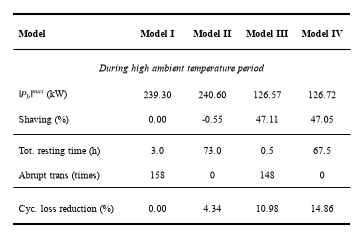

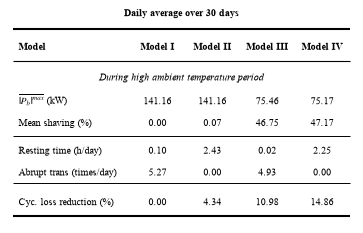

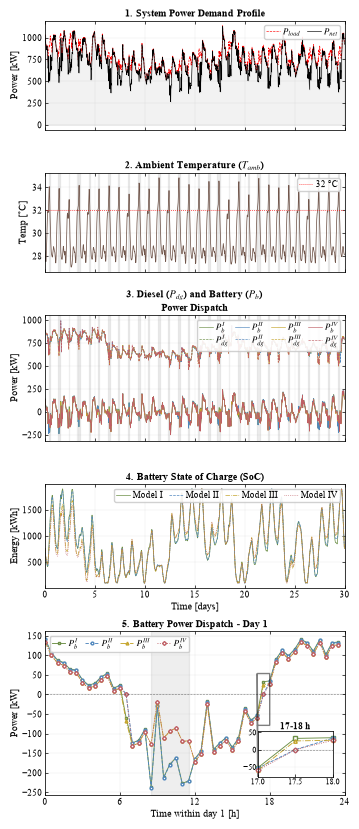

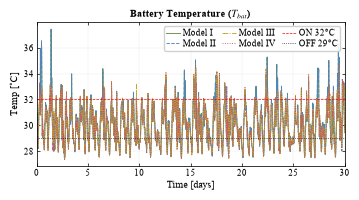

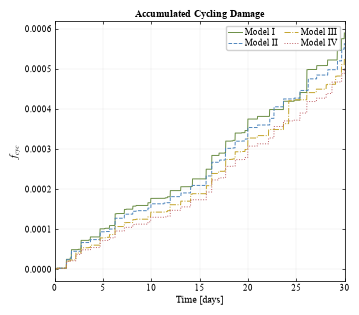

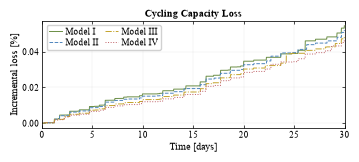

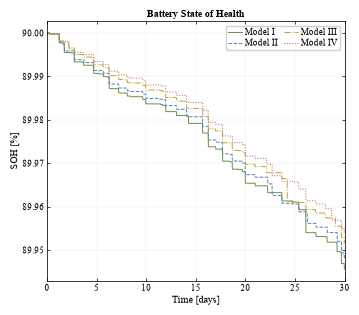

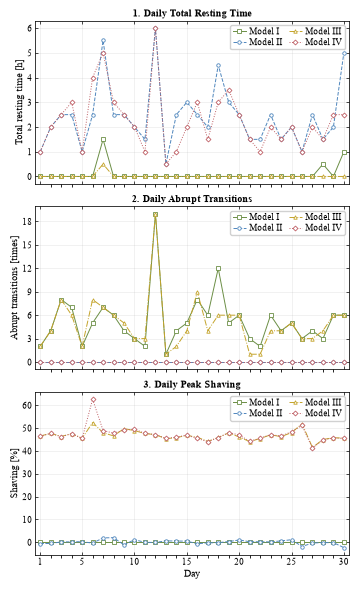

Assessed 4 continuous profiles: 1440 samples, 719.5 h, initial SOH 90%.
Comparison table, 30-day plots (PNG/PDF) and Excel saved to: D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results\assessment


In [5]:
# Scenario integration: analytical 15-minute hysteresis; continuous 720-hour thermal trace.
# CONTINUOUS 30-DAY ASSESSMENT - SAVED RESULTS ONLY; NO PMP SOLVES
# Run this cell directly. It reads 30days_results and inherits cell 4 assessment
# settings when they are already defined; the defaults below match that cell.
from pathlib import Path as _assessment30_Path
from dataclasses import asdict as _assessment30_asdict
import numpy as _assessment30_np
import pandas as _assessment30_pd
import matplotlib.pyplot as _assessment30_plt
import bess_pipeline as _assessment30_ieee
from bess_pipeline import (
    CyclingParameters as _assessment30_CyclingParameters,
    assess_cycling_degradation as _assessment30_cycling,
    with_initial_soh as _assessment30_with_initial_soh,
)

# ================= EDIT ASSESSMENT SETTINGS HERE =================
ASSESS30_INPUT_DIR = OUTPUT_DIR_30DAYS
ASSESS30_OUTPUT_DIR = ASSESS30_INPUT_DIR / 'assessment'
ASSESS30_INITIAL_SOH_PCT = ASSESSMENT_INITIAL_SOH_PCT
ASSESS30_NOMINAL_ENERGY_KWH = float(globals().get('PAIR_NOMINAL_ENERGY_KWH', 2000.0))
ASSESS30_REST_THRESHOLD_KW = 1.0  # epsilon [kW]: abs(Pb(t)) <= epsilon
ASSESS30_REST_PRODUCT_THRESHOLD_KW2 = 0.5  # strict abs(Pb(t)*Pb(t-1)) limit [kW^2]
ASSESS30_HIGH_AMBIENT_C = float(globals().get('PAIR_HIGH_AMBIENT_C', 32.0))
ASSESS30_THERMAL = dict(
    G=THERMAL_CONFIG.G, C=THERMAL_CONFIG.C, cp=THERMAL_CONFIG.Cp, Cp=THERMAL_CONFIG.Cp,
    r=THERMAL_CONFIG.r, Ts=THERMAL_CONFIG.Ts, r_bat=THERMAL_CONFIG.r_bat, V_nom=THERMAL_CONFIG.V_nom,
    threshold_C=THERMAL_CONFIG.Ton, Ton=THERMAL_CONFIG.Ton, Toff=THERMAL_CONFIG.Toff, COP=THERMAL_CONFIG.COP,
    inner_step_s=THERMAL_CONFIG.step_seconds, thermal_step_seconds=THERMAL_CONFIG.step_seconds)
ASSESS30_INITIAL_TEMPERATURE_C = THERMAL_CONFIG.initial_temperature_c
ASSESS30_CYCLING_PARAMETERS = globals().get('PAIR_CYCLING_PARAMETERS',
                                         _assessment30_CyclingParameters())
ASSESS30_EXPECTED_DAYS = 30
ASSESS30_ENERGY_CYCLE_TOL_KWH = float(globals().get('BC_REPORT_TOL_30DAYS', 1e-3))
ASSESS30_DPI = _assessment30_ieee.IEEE_DPI
ASSESS30_DETAIL_RANK = 2  # Rank daily max high-ambient |Pb| across all four models
ASSESS30_ZOOM_START_H = 17.0
ASSESS30_ZOOM_END_H = 18.0
ASSESS30_MAIN_FIGURE_HEIGHT_IN = 8.2  # Final printed height; width remains one column
ASSESS30_DAILY_FIGURE_HEIGHT_IN = 5.8  # Approximately two-thirds of the text-page height


_assessment30_models = ('I', 'II', 'III', 'IV')
_assessment30_styles = {
    'I': dict(color='#6b8e45', linestyle='-', marker='s'),
    'II': dict(color='#4f86bd', linestyle='--', marker='o'),
    'III': dict(color='#c4a42b', linestyle='-.', marker='^'),
    'IV': dict(color='#bf5f65', linestyle=':', marker='D'),
}
_assessment30_aliases = {
    'time_hour': ('time_hour', 'Time_hour'),
    'P_net_kW': ('P_net_kW', 'Pnet_kW'),
    'P_battery_kW': ('P_battery_kW', 'Pb_kW'),
    'P_diesel_kW': ('P_diesel_kW', 'Pdg_kW'),
    'E_battery_kWh': ('E_battery_kWh', 'Eb_kWh'),
    'Tamb_degC': ('ambient_temperature_degC', 'Tamb_degC'),
    'P_load_kW': ('P_load_kW',),
    'P_pv_kW': ('P_pv_kW',),
    'P_self_consumption_kW': ('P_self_consumption_kW',),
}


def _assessment30_read(path):
    raw = _assessment30_pd.read_excel(path, sheet_name=0)
    data = _assessment30_pd.DataFrame(index=raw.index)
    for target, aliases in _assessment30_aliases.items():
        for alias in aliases:
            if alias in raw:
                data[target] = _assessment30_pd.to_numeric(raw[alias], errors='raise')
                break
    required = ('time_hour', 'P_net_kW', 'P_battery_kW', 'P_diesel_kW', 'E_battery_kWh')
    missing = set(required)-set(data.columns)
    if missing or len(data) < 2:
        raise ValueError(f'{path.name}: missing {sorted(missing)} or insufficient samples.')
    if not _assessment30_np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError(f'{path.name}: input contains nonfinite values.')
    if not (_assessment30_np.diff(data.time_hour) > 0).all():
        raise ValueError(f'{path.name}: time must be strictly increasing.')
    return data


def _assessment30_temperature(time, power, ambient):
    from bess_pipeline import simulate_thermal
    return simulate_thermal(time, power, ambient, THERMAL_CONFIG,
                            duration_hours=THERMAL_DURATION_HOURS)



def _assessment30_rest_mask(power, epsilon_kw, product_threshold_kw2):
    """Attribute rest to the current sample only; the first has no predecessor."""
    power = _assessment30_np.asarray(power, dtype=float)
    resting = _assessment30_np.zeros(power.shape, dtype=bool)
    if power.size > 1:
        resting[1:] = (
            (_assessment30_np.abs(power[1:]) <= epsilon_kw)
            & (_assessment30_np.abs(power[1:]*power[:-1]) < product_threshold_kw2)
        )
    return resting


def _assessment30_daily_metrics(frames, time_hour, ambient, number_of_days,
                                rest_threshold_kw, high_ambient_c, rest_product_threshold_kw2):
    """Daily metrics from one continuous run, retaining transitions across midnight."""
    elapsed = _assessment30_np.asarray(time_hour, dtype=float)-float(time_hour[0])
    node_day = _assessment30_np.floor(elapsed/24).astype(int)+1
    ambient = _assessment30_np.asarray(ambient, dtype=float)
    rows = []
    for model, frame in frames.items():
        power = frame.P_battery_kW.to_numpy(dtype=float)
        state = _assessment30_np.where(power > rest_threshold_kw, 1,
                    _assessment30_np.where(power < -rest_threshold_kw, -1, 0))
        abrupt = state[1:]*state[:-1] == -1
        resting = _assessment30_rest_mask(power, rest_threshold_kw, rest_product_threshold_kw2)
        for day in range(1, number_of_days+1):
            high = (node_day == day) & (ambient >= high_ambient_c)
            # Allocate each left-node resting interval by its actual overlap with this day.
            # The final day ends at the last saved node; no extra half-hour is invented.
            hours = _assessment30_np.maximum(0.,
                _assessment30_np.minimum(elapsed[1:], day*24.)
                -_assessment30_np.maximum(elapsed[:-1], (day-1)*24.))
            rows.append(dict(
                Day=day, Model=f'Model {model}',
                Peak_high_ambient_kW=float(_assessment30_np.abs(power[high]).max())
                                     if high.any() else _assessment30_np.nan,
                Resting_time_h=float(hours[resting[:-1]].sum()),
                Abrupt_transitions=int(_assessment30_np.count_nonzero(abrupt & (node_day[1:] == day)))))
    daily = _assessment30_pd.DataFrame(rows)
    base = daily.loc[daily.Model == 'Model I'].set_index('Day').Peak_high_ambient_kW
    denominator = daily.Day.map(base)
    denominator = denominator.where(denominator > 0)
    daily['Shaving_pct'] = 100*(1-daily.Peak_high_ambient_kW/denominator)
    return daily[['Day', 'Model', 'Peak_high_ambient_kW', 'Shaving_pct',
                  'Resting_time_h', 'Abrupt_transitions']]


def _assessment30_save_figure(figure, stem):
    _assessment30_ieee.save_ieee_figure(
        figure, ASSESS30_OUTPUT_DIR / stem, dpi=ASSESS30_DPI)


# Validate settings without modifying any simulation inputs or solver configuration.
if (not _assessment30_np.isfinite([ASSESS30_INITIAL_SOH_PCT, ASSESS30_NOMINAL_ENERGY_KWH,
                                  ASSESS30_REST_THRESHOLD_KW, ASSESS30_HIGH_AMBIENT_C,
                                  ASSESS30_REST_PRODUCT_THRESHOLD_KW2,
                                  ASSESS30_ENERGY_CYCLE_TOL_KWH]).all()
        or not 0 < ASSESS30_INITIAL_SOH_PCT <= 100 or ASSESS30_NOMINAL_ENERGY_KWH <= 0
        or ASSESS30_REST_THRESHOLD_KW < 0 or ASSESS30_REST_PRODUCT_THRESHOLD_KW2 <= 0
        or ASSESS30_ENERGY_CYCLE_TOL_KWH < 0):
    raise ValueError('Invalid 30-day assessment settings.')
if (not isinstance(ASSESS30_DETAIL_RANK, (int, _assessment30_np.integer))
        or not 1 <= ASSESS30_DETAIL_RANK <= ASSESS30_EXPECTED_DAYS
        or not _assessment30_np.isfinite([ASSESS30_ZOOM_START_H, ASSESS30_ZOOM_END_H]).all()
        or not 0 <= ASSESS30_ZOOM_START_H < ASSESS30_ZOOM_END_H <= 24):
    raise ValueError('Choose a valid day rank and a zoom window within 0..24 h.')
_assessment30_p = ASSESS30_THERMAL
if (not _assessment30_np.isfinite(list(_assessment30_p.values())).all()
        or min(_assessment30_p[k] for k in ('C', 'cp', 'r', 'V_nom', 'inner_step_s')) <= 0
        or min(_assessment30_p['G'], _assessment30_p['r_bat']) < 0
        or min(_assessment30_p['Ts'], _assessment30_p['threshold_C']) <= -273.15
):
    raise ValueError('Invalid or unstable thermal settings.')

assessment30_frames = {
    model: _assessment30_read(ASSESS30_INPUT_DIR / f'Model_{model}_results_30days.xlsx')
    for model in _assessment30_models
}
_assessment30_base = assessment30_frames['I']
_assessment30_time = _assessment30_base.time_hour.to_numpy(dtype=float)
_assessment30_dt = _assessment30_np.diff(_assessment30_time)
if (not _assessment30_np.allclose(_assessment30_dt, _assessment30_dt[0], rtol=0, atol=1e-8)
        or not _assessment30_np.isclose(_assessment30_time[-1]-_assessment30_time[0]
                                       +_assessment30_dt[0], ASSESS30_EXPECTED_DAYS*24,
                                       rtol=0, atol=1e-6)):
    raise ValueError('Expected uniform samples spanning 30 daily profiles.')
_assessment30_days = (_assessment30_time-_assessment30_time[0])/24
_assessment30_ambient_models = [m for m in _assessment30_models if 'Tamb_degC' in assessment30_frames[m]]
if not _assessment30_ambient_models:
    raise ValueError('Saved results contain no ambient temperature profile.')
_assessment30_ambient = assessment30_frames[_assessment30_ambient_models[0]].Tamb_degC.to_numpy(dtype=float)
_assessment30_validation = []
for _assessment30_model, _assessment30_frame in assessment30_frames.items():
    for _assessment30_column in ('time_hour', 'P_net_kW'):
        if (len(_assessment30_frame) != len(_assessment30_base)
                or not _assessment30_np.allclose(_assessment30_frame[_assessment30_column],
                                                 _assessment30_base[_assessment30_column],
                                                 rtol=0, atol=1e-6)):
            raise ValueError(f'Model {_assessment30_model}: mismatched {_assessment30_column}.')
    for _assessment30_column in ('P_load_kW', 'P_pv_kW', 'P_self_consumption_kW'):
        if (_assessment30_column in _assessment30_frame and _assessment30_column in _assessment30_base
                and not _assessment30_np.allclose(_assessment30_frame[_assessment30_column],
                                                 _assessment30_base[_assessment30_column], rtol=0, atol=1e-6)):
            raise ValueError(f'Model {_assessment30_model}: mismatched {_assessment30_column}.')
    if ('Tamb_degC' in _assessment30_frame
            and not _assessment30_np.allclose(_assessment30_frame.Tamb_degC, _assessment30_ambient,
                                             rtol=0, atol=1e-6)):
        raise ValueError(f'Model {_assessment30_model}: mismatched ambient temperature.')
    _assessment30_endpoints = _assessment30_frame.E_battery_kWh.iloc[[0, -1]].to_numpy(dtype=float)
    if (abs(_assessment30_endpoints[1]-_assessment30_endpoints[0]) > ASSESS30_ENERGY_CYCLE_TOL_KWH
            or not _assessment30_np.allclose(_assessment30_endpoints,
                                             _assessment30_base.E_battery_kWh.iloc[[0, -1]],
                                             rtol=0, atol=ASSESS30_ENERGY_CYCLE_TOL_KWH)):
        raise ValueError(f'Model {_assessment30_model}: cyclic/baseline energy boundary mismatch.')
    _assessment30_frame['Tamb_degC'] = _assessment30_ambient.copy()
    _assessment30_validation.append(dict(
        Model=_assessment30_model, Samples=len(_assessment30_frame),
        First_hour=_assessment30_time[0], Last_hour=_assessment30_time[-1],
        Endpoint_gap_kWh=abs(_assessment30_endpoints[1]-_assessment30_endpoints[0]),
        Source_file=str((ASSESS30_INPUT_DIR / f'Model_{_assessment30_model}_results_30days.xlsx').resolve()),
        Ambient_source=', '.join(_assessment30_ambient_models)))

# Process each complete 30-day trace ONCE. Thermal state and SOH never reset at day boundaries.
assessment30_degradation = {}
assessment30_thermal_results = {}
_assessment30_rows = []
for _assessment30_model, _assessment30_frame in assessment30_frames.items():
    _assessment30_power = _assessment30_frame.P_battery_kW.to_numpy(dtype=float)
    _assessment30_soc = _assessment30_frame.E_battery_kWh.to_numpy(dtype=float)/ASSESS30_NOMINAL_ENERGY_KWH
    _assessment30_thermal_result = _assessment30_temperature(
        _assessment30_time, _assessment30_power, _assessment30_ambient)
    assessment30_thermal_results[_assessment30_model] = _assessment30_thermal_result
    # Cycling/SOC remains on the original electrical nodes (no fictitious SOC at 720 h).
    _assessment30_temperature_trace = _assessment30_np.interp(
        _assessment30_time, _assessment30_thermal_result.nodes.time_hour,
        _assessment30_thermal_result.nodes.T_battery_degC)
    _assessment30_result = _assessment30_with_initial_soh(
        _assessment30_cycling(_assessment30_time, _assessment30_soc, _assessment30_temperature_trace,
                             ASSESS30_CYCLING_PARAMETERS), ASSESS30_INITIAL_SOH_PCT)
    assessment30_degradation[_assessment30_model] = _assessment30_result
    _assessment30_frame['Time_day'] = _assessment30_days
    _assessment30_frame['SoC_fraction'] = _assessment30_soc
    _assessment30_frame['T_battery_degC'] = _assessment30_temperature_trace
    _assessment30_state = _assessment30_np.where(_assessment30_power > ASSESS30_REST_THRESHOLD_KW, 1,
        _assessment30_np.where(_assessment30_power < -ASSESS30_REST_THRESHOLD_KW, -1, 0))
    _assessment30_resting = _assessment30_rest_mask(
        _assessment30_power, ASSESS30_REST_THRESHOLD_KW, ASSESS30_REST_PRODUCT_THRESHOLD_KW2)
    _assessment30_high = _assessment30_ambient >= ASSESS30_HIGH_AMBIENT_C
    _assessment30_rows.append(dict(
        Model=f'Model {_assessment30_model}',
        Peak_high_ambient_kW=float(_assessment30_np.abs(_assessment30_power[_assessment30_high]).max())
                             if _assessment30_high.any() else _assessment30_np.nan,
        Resting_time_h=float(_assessment30_dt[_assessment30_resting[:-1]].sum()),
        Abrupt_transitions=int(_assessment30_np.count_nonzero(
            _assessment30_state[1:]*_assessment30_state[:-1] == -1)),
        Initial_SOH_pct=ASSESS30_INITIAL_SOH_PCT,
        Incremental_capacity_loss_pct=_assessment30_result.summary['incremental_capacity_loss_pct'],
        Final_SOH_pct=_assessment30_result.summary['soh_pct'],
        Cycling_damage=_assessment30_result.summary['f_cyc'],
        Rainflow_EFC=_assessment30_result.summary['rainflow_EFC'],
        Maximum_battery_temperature_degC=_assessment30_thermal_result.summary['T_max_degC'],
        Minimum_battery_temperature_degC=_assessment30_thermal_result.summary['T_min_degC'],
        Mean_battery_temperature_degC=_assessment30_thermal_result.summary['T_mean_degC']))
assessment30_summary = _assessment30_pd.DataFrame(_assessment30_rows).set_index('Model')
_assessment30_peak0 = assessment30_summary.iloc[0].Peak_high_ambient_kW
_assessment30_loss0 = assessment30_summary.iloc[0].Incremental_capacity_loss_pct
assessment30_summary['Shaving_pct'] = (
    100*(1-assessment30_summary.Peak_high_ambient_kW/_assessment30_peak0)
    if _assessment30_np.isfinite(_assessment30_peak0) and _assessment30_peak0 > 0 else _assessment30_np.nan)
assessment30_summary['Cycling_loss_reduction_pct'] = (
    100*(1-assessment30_summary.Incremental_capacity_loss_pct/_assessment30_loss0)
    if _assessment30_loss0 > 0 else _assessment30_np.nan)
assessment30_comparison = assessment30_summary[[
    'Peak_high_ambient_kW', 'Shaving_pct', 'Resting_time_h',
    'Abrupt_transitions', 'Cycling_loss_reduction_pct']].T
assessment30_comparison.index = ['|Pb|max (kW)', 'Shaving (%)', 'Tot. resting time (h)',
                               'Abrupt trans (times)', 'Cyc. loss reduction (%)']

# Daily reporting does not reset the continuous thermal or degradation simulation.
assessment30_daily = _assessment30_daily_metrics(
    assessment30_frames, _assessment30_time, _assessment30_ambient,
    ASSESS30_EXPECTED_DAYS, ASSESS30_REST_THRESHOLD_KW, ASSESS30_HIGH_AMBIENT_C,
    ASSESS30_REST_PRODUCT_THRESHOLD_KW2)

# Additional daily-average table. Keep the original monthly comparison unchanged.
_assessment30_daily_means = assessment30_daily.groupby('Model')[
    ['Peak_high_ambient_kW', 'Shaving_pct']].mean().reindex(assessment30_summary.index)
assessment30_daily_average_summary = _assessment30_pd.DataFrame(index=assessment30_summary.index)
assessment30_daily_average_summary['Peak_high_ambient_kW'] = _assessment30_daily_means.Peak_high_ambient_kW
assessment30_daily_average_summary['Shaving_pct'] = _assessment30_daily_means.Shaving_pct
assessment30_daily_average_summary['Resting_time_h'] = assessment30_summary.Resting_time_h / ASSESS30_EXPECTED_DAYS
assessment30_daily_average_summary['Abrupt_transitions'] = assessment30_summary.Abrupt_transitions / ASSESS30_EXPECTED_DAYS
# Dividing both models' cycling losses by 30 leaves their relative reduction unchanged.
assessment30_daily_average_summary['Cycling_loss_reduction_pct'] = assessment30_summary.Cycling_loss_reduction_pct
assessment30_daily_average_comparison = assessment30_daily_average_summary.T
assessment30_daily_average_comparison.index = [
    'Mean daily |Pb|max (kW)', 'Mean daily shaving (%)', 'Resting time (h/day)',
    'Abrupt trans (times/day)', 'Cyc. loss reduction (%)']

# Select the second-ranked DAY, not the second sample or one model's ranking.
assessment30_day_peak_ranking = assessment30_daily.pivot(
    index='Day', columns='Model', values='Peak_high_ambient_kW')
assessment30_day_peak_ranking['Ranking_peak_kW'] = assessment30_day_peak_ranking.max(axis=1)
assessment30_day_peak_ranking = assessment30_day_peak_ranking.dropna(subset=['Ranking_peak_kW']).reset_index().sort_values(
    ['Ranking_peak_kW', 'Day'], ascending=[False, True], kind='stable').reset_index(drop=True)
assessment30_day_peak_ranking.insert(0, 'Rank', _assessment30_np.arange(1, len(assessment30_day_peak_ranking)+1))
if len(assessment30_day_peak_ranking) < ASSESS30_DETAIL_RANK:
    raise ValueError('Not enough days with high-ambient peak data for the requested rank.')
ASSESS30_DETAIL_DAY = int(assessment30_day_peak_ranking.iloc[ASSESS30_DETAIL_RANK-1].Day)
_assessment30_detail_start = (ASSESS30_DETAIL_DAY - 1) * 24.0
_assessment30_elapsed = _assessment30_time - _assessment30_time[0]
_assessment30_detail_indices = _assessment30_np.flatnonzero(
    (_assessment30_elapsed >= _assessment30_detail_start)
    & (_assessment30_elapsed < _assessment30_detail_start + 24.0))
_assessment30_detail_hours = _assessment30_elapsed[_assessment30_detail_indices] - _assessment30_detail_start
_assessment30_detail_power = {
    m: assessment30_frames[m].P_battery_kW.to_numpy(dtype=float) for m in _assessment30_models}
_assessment30_detail_rest = {
    m: _assessment30_rest_mask(power, ASSESS30_REST_THRESHOLD_KW, ASSESS30_REST_PRODUCT_THRESHOLD_KW2)
    for m, power in _assessment30_detail_power.items()}
# A true transition in I/III, with II/IV resting at the same saved sample.
_assessment30_transition = _assessment30_np.ones(len(_assessment30_time), dtype=bool)
for _assessment30_model in ('I', 'III'):
    _assessment30_power = _assessment30_detail_power[_assessment30_model]
    _assessment30_transition &= _assessment30_np.r_[False, _assessment30_power[1:]*_assessment30_power[:-1] < 0]
_assessment30_zoom_candidates = _assessment30_detail_indices[
    _assessment30_detail_rest['II'][_assessment30_detail_indices]
    & _assessment30_detail_rest['IV'][_assessment30_detail_indices]
    & _assessment30_transition[_assessment30_detail_indices]
    & (_assessment30_np.abs(_assessment30_detail_power['I'][_assessment30_detail_indices]) > ASSESS30_REST_THRESHOLD_KW)
    & (_assessment30_np.abs(_assessment30_detail_power['III'][_assessment30_detail_indices]) > ASSESS30_REST_THRESHOLD_KW)
    & (_assessment30_detail_hours >= ASSESS30_ZOOM_START_H)
    & (_assessment30_detail_hours <= ASSESS30_ZOOM_END_H)]
assessment30_zoom_sample_index = None
if _assessment30_zoom_candidates.size:
    _assessment30_zoom_contrast = _assessment30_np.minimum(
        _assessment30_np.abs(_assessment30_detail_power['I'][_assessment30_zoom_candidates]),
        _assessment30_np.abs(_assessment30_detail_power['III'][_assessment30_zoom_candidates]))
    assessment30_zoom_sample_index = int(_assessment30_zoom_candidates[_assessment30_np.argmax(_assessment30_zoom_contrast)])
assessment30_selected_day_metrics = assessment30_daily.loc[
    assessment30_daily.Day == ASSESS30_DETAIL_DAY].set_index('Model').reindex(assessment30_summary.index)[
        ['Peak_high_ambient_kW', 'Shaving_pct']].rename(columns={'Shaving_pct': 'Shaving_high_ambient_pct'})
assessment30_selected_day_metrics.insert(0, 'Peak_full_day_kW', [
    float(_assessment30_np.abs(_assessment30_detail_power[m][_assessment30_detail_indices]).max())
    for m in _assessment30_models])
_assessment30_detail_peak0 = assessment30_selected_day_metrics.iloc[0].Peak_full_day_kW
assessment30_selected_day_metrics.insert(1, 'Shaving_full_day_pct',
    100*(1-assessment30_selected_day_metrics.Peak_full_day_kW/_assessment30_detail_peak0)
    if _assessment30_detail_peak0 > 0 else _assessment30_np.nan)
assessment30_selected_day_metrics.insert(0, 'Day', ASSESS30_DETAIL_DAY)
print(f'Selected day {ASSESS30_DETAIL_DAY}: rank {ASSESS30_DETAIL_RANK} by max high-ambient |Pb| across all four models.')
print(f'High ambient: Tamb >= {ASSESS30_HIGH_AMBIENT_C:g} degC; ties ranked by earlier day first.')
for _assessment30_model_name, _assessment30_metric_row in assessment30_selected_day_metrics.iterrows():
    print(f'{_assessment30_model_name}: Ppeak(high Tamb)={_assessment30_metric_row.Peak_high_ambient_kW:.2f} kW; '
          f'shaving(high Tamb)={_assessment30_metric_row.Shaving_high_ambient_pct:.2f}%; '
          f'Ppeak(full day)={_assessment30_metric_row.Peak_full_day_kW:.2f} kW')
if assessment30_zoom_sample_index is not None:
    print('Transition zoom at '+str(float(_assessment30_elapsed[assessment30_zoom_sample_index]-_assessment30_detail_start))
          +' h; '+ '; '.join(f'Pb_{m}={_assessment30_detail_power[m][assessment30_zoom_sample_index]:.6f} kW'
                             for m in _assessment30_models))
else:
    print('No common II/IV rest sample at an I/III sign transition in the chosen day; no transition inset is fabricated.')

# Preserve the original solve labels for provenance; they do not filter the saved profiles.
_assessment30_report_path = ASSESS30_INPUT_DIR / 'Solver_report_30days.xlsx'
assessment30_solver_report = (_assessment30_pd.read_excel(_assessment30_report_path)
                              if _assessment30_report_path.exists() else _assessment30_pd.DataFrame())
ASSESS30_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
_assessment30_settings = dict(
    initial_soh_pct=ASSESS30_INITIAL_SOH_PCT, nominal_energy_kwh=ASSESS30_NOMINAL_ENERGY_KWH,
    high_ambient_C=ASSESS30_HIGH_AMBIENT_C, rest_threshold_kw=ASSESS30_REST_THRESHOLD_KW,
    rest_product_threshold_kw2=ASSESS30_REST_PRODUCT_THRESHOLD_KW2,
    detail_day=ASSESS30_DETAIL_DAY, detail_day_rank=ASSESS30_DETAIL_RANK,
    detail_day_ranking='Daily maximum of high-ambient absolute battery-power peaks across all four models; earlier day breaks ties',
    detail_zoom_start_h=ASSESS30_ZOOM_START_H, detail_zoom_end_h=ASSESS30_ZOOM_END_H,
    detail_zoom_sample_index=assessment30_zoom_sample_index,
    detail_peak_convention='Absolute battery-power peak; full-day and high-ambient peaks have separate Model-I shaving baselines',
    resting_convention='Current abs(Pb)<=1 kW AND abs(Pb*previous Pb)<0.5 kW^2; first sample excluded; each left-node interval counted once', 
    initial_temperature_C=str(ASSESS30_INITIAL_TEMPERATURE_C), **ASSESS30_THERMAL,
    **{'cycling_'+key: value for key, value in _assessment30_asdict(ASSESS30_CYCLING_PARAMETERS).items()},
    observed_duration_h=float(_assessment30_time[-1]-_assessment30_time[0]),
    conventions='Continuous thermal state; whole-profile rainflow once; initial SOH once; left-node resting time; adjacent sampled transitions',
    endpoint_convention='Electrical/SOC/aging: 0..719.5 h; thermal/cooling: 0..720 h with last P/Tamb held',
    thermal_integration='Analytical original ODE; 900 s control; command held within each interval',
    activation_convention='Count OFF-to-ON commands at interval starts, including t=0 if commanded ON',
    daily_convention='Day d = [24*(d-1),24*d) h; resting intervals split at midnight; abrupt transitions assigned to later endpoint day',
    daily_shaving_convention='High-ambient peak compared with Model I of the SAME day; undefined if no high-temperature samples or zero baseline peak',
    daily_average_convention='Mean of daily high-ambient peaks and daily shaving percentages; resting/abrupt totals divided by 30; relative cycling-loss reduction unchanged; undefined daily peaks/shaving remain NaN and are omitted from the mean',
    capacity_loss_convention='Incremental loss in percentage points of original nominal capacity',
    damage_time_convention='Offline attribution at later rainflow endpoint; each cycle counted once',
    source_status_policy='Use finite comparable saved profiles; preserve solver report; BVP status is diagnostic only',
    chemistry='Xu LMO example coefficients inherited from project; not calibrated for LFP',
    calendar_aging_included=False)
with _assessment30_pd.ExcelWriter(ASSESS30_OUTPUT_DIR / 'Assessment_30days.xlsx', engine='openpyxl') as _assessment30_writer:
    assessment30_comparison.to_excel(_assessment30_writer, sheet_name='Comparison')
    assessment30_daily_average_comparison.to_excel(_assessment30_writer, sheet_name='Comparison_daily_average')
    assessment30_summary.to_excel(_assessment30_writer, sheet_name='Summary')
    assessment30_daily.to_excel(_assessment30_writer, sheet_name='Daily_metrics', index=False)
    assessment30_selected_day_metrics.to_excel(_assessment30_writer, sheet_name='Selected_day_metrics')
    assessment30_day_peak_ranking.to_excel(_assessment30_writer, sheet_name='Day_peak_ranking', index=False)
    _assessment30_pd.DataFrame(_assessment30_validation).to_excel(
        _assessment30_writer, sheet_name='Source_validation', index=False)
    assessment30_solver_report.to_excel(_assessment30_writer, sheet_name='Original_solver_report', index=False)
    _assessment30_pd.DataFrame(_assessment30_settings.items(), columns=['Parameter', 'Value']).to_excel(
        _assessment30_writer, sheet_name='Assumptions', index=False)
    _assessment30_pd.DataFrame([dict(Model=f'Model {m}', **result.summary) for m,result in assessment30_thermal_results.items()]).set_index('Model').to_excel(
        _assessment30_writer, sheet_name='Thermal_summary')
    _assessment30_pd.DataFrame([dict(Model=f'Model {m}', **result.validation) for m,result in assessment30_thermal_results.items()]).set_index('Model').to_excel(
        _assessment30_writer, sheet_name='Thermal_validation')
    for _assessment30_model in _assessment30_models:
        assessment30_thermal_results[_assessment30_model].nodes.to_excel(_assessment30_writer, sheet_name=f'Thermal_nodes_{_assessment30_model}', index=False)
        assessment30_thermal_results[_assessment30_model].intervals.to_excel(_assessment30_writer, sheet_name=f'Thermal_intervals_{_assessment30_model}', index=False)
        assessment30_thermal_results[_assessment30_model].daily.to_excel(_assessment30_writer, sheet_name=f'Thermal_daily_{_assessment30_model}', index=False)
        assessment30_frames[_assessment30_model].to_excel(
            _assessment30_writer, sheet_name=f'Simulation_{_assessment30_model}', index=False)
        assessment30_degradation[_assessment30_model].history.to_excel(
            _assessment30_writer, sheet_name=f'History_{_assessment30_model}', index=False)
        assessment30_degradation[_assessment30_model].cycles.to_excel(
            _assessment30_writer, sheet_name=f'Cycles_{_assessment30_model}', index=False)

with _assessment30_plt.rc_context(_assessment30_ieee.IEEE_RC):
    # Comparison table: same five rows and Model I baseline as the reference image.
    _assessment30_fig, _assessment30_ax = _assessment30_plt.subplots(figsize=_assessment30_ieee.column_size(1.75))
    _assessment30_ax.set(xlim=(0, 1), ylim=(0, 1)); _assessment30_ax.axis('off')
    for _assessment30_y, _assessment30_width in [( .98, 1.5), (.82, .8), (.44, .7), (.20, .7), (.035, 1.5)]:
        _assessment30_ax.hlines(_assessment30_y, .01, .99, color='black', linewidth=_assessment30_width)
    _assessment30_xs = [.43, .59, .75, .91]
    _assessment30_ax.text(.025, .875, 'Model', fontsize=7, fontweight='bold')
    for _assessment30_x, _assessment30_model in zip(_assessment30_xs, _assessment30_models):
        _assessment30_ax.text(_assessment30_x, .875, f'Model {_assessment30_model}',
                              ha='center', fontsize=7, fontweight='bold')
    _assessment30_ax.text(.5, .72, 'During high ambient temperature period',
                          ha='center', fontsize=7, fontstyle='italic')
    for _assessment30_i, (_assessment30_y, _assessment30_label) in enumerate(zip(
            [.60, .49, .35, .24, .09],
            [r'$|P_b|^{max}$ (kW)', 'Shaving (%)', 'Tot. resting time (h)',
             'Abrupt trans (times)', 'Cyc. loss reduction (%)'])):
        _assessment30_ax.text(.025, _assessment30_y, _assessment30_label, fontsize=7)
        for _assessment30_x, _assessment30_column in zip(_assessment30_xs, assessment30_comparison.columns):
            _assessment30_value = assessment30_comparison.iloc[_assessment30_i][ _assessment30_column]
            _assessment30_text = ('N/A' if not _assessment30_np.isfinite(_assessment30_value)
                                 else f'{_assessment30_value:.0f}' if _assessment30_i == 3
                                 else f'{_assessment30_value:.1f}' if _assessment30_i == 2
                                 else f'{_assessment30_value:.2f}')
            _assessment30_ax.text(_assessment30_x, _assessment30_y, _assessment30_text,
                                  ha='center', fontsize=7)
    _assessment30_fig.subplots_adjust(left=.01, right=.99, top=.99, bottom=.01)
    _assessment30_save_figure(_assessment30_fig, 'Model_comparison_30days')

    # Additional comparison table: daily averages, with the same layout and type sizes.
    _assessment30_fig, _assessment30_ax = _assessment30_plt.subplots(figsize=_assessment30_ieee.column_size(1.75))
    _assessment30_ax.set(xlim=(0, 1), ylim=(0, 1)); _assessment30_ax.axis('off')
    _assessment30_ax.text(.5, 1.045, 'Daily average over 30 days', ha='center', fontsize=7, fontweight='bold')
    for _assessment30_y, _assessment30_width in [( .98, 1.5), (.82, .8), (.44, .7), (.20, .7), (.035, 1.5)]:
        _assessment30_ax.hlines(_assessment30_y, .01, .99, color='black', linewidth=_assessment30_width)
    _assessment30_xs = [.43, .59, .75, .91]
    _assessment30_ax.text(.025, .875, 'Model', fontsize=7, fontweight='bold')
    for _assessment30_x, _assessment30_model in zip(_assessment30_xs, _assessment30_models):
        _assessment30_ax.text(_assessment30_x, .875, f'Model {_assessment30_model}',
                              ha='center', fontsize=7, fontweight='bold')
    _assessment30_ax.text(.5, .72, 'During high ambient temperature period',
                          ha='center', fontsize=7, fontstyle='italic')
    for _assessment30_i, (_assessment30_y, _assessment30_label) in enumerate(zip(
            [.60, .49, .35, .24, .09],
            [r'$\overline{|P_b|^{max}}$ (kW)', 'Mean shaving (%)', 'Resting time (h/day)',
             'Abrupt trans (times/day)', 'Cyc. loss reduction (%)'])):
        _assessment30_ax.text(.025, _assessment30_y, _assessment30_label, fontsize=7)
        for _assessment30_x, _assessment30_column in zip(_assessment30_xs, assessment30_daily_average_comparison.columns):
            _assessment30_value = assessment30_daily_average_comparison.iloc[_assessment30_i][ _assessment30_column]
            _assessment30_text = ('N/A' if not _assessment30_np.isfinite(_assessment30_value)
                                 else f'{_assessment30_value:.2f}')
            _assessment30_ax.text(_assessment30_x, _assessment30_y, _assessment30_text,
                                  ha='center', fontsize=7)
    _assessment30_fig.subplots_adjust(left=.01, right=.99, top=.88, bottom=.01)
    _assessment30_save_figure(_assessment30_fig, 'Model_comparison_daily_average_30days')

    # Five-panel, one-column figure. Only the first four panels share the month axis.
    _assessment30_fig, _assessment30_axes = _assessment30_plt.subplots(
        5, 1, figsize=(_assessment30_ieee.IEEE_COLUMN_WIDTH_IN, ASSESS30_MAIN_FIGURE_HEIGHT_IN),
        gridspec_kw={'height_ratios': [1., .9, 1.15, .95, 1.5]})
    for _assessment30_ax in _assessment30_axes[1:4]:
        _assessment30_ax.sharex(_assessment30_axes[0])
    _assessment30_axes[0].plot(_assessment30_days, _assessment30_base.P_load_kW,
        color='red', linestyle='--', linewidth=.45, label=r'$P_{load}$')
    _assessment30_axes[0].plot(_assessment30_days, _assessment30_base.P_net_kW,
        color='black', linewidth=.45, label=r'$P_{net}$')
    _assessment30_axes[0].fill_between(_assessment30_days, 0, _assessment30_base.P_net_kW,
        color='black', alpha=.05)
    _assessment30_axes[0].set(title='1. System Power Demand Profile', ylabel='Power [kW]')
    _assessment30_axes[0].legend(loc='upper right', ncol=2)
    _assessment30_axes[1].plot(_assessment30_days, _assessment30_ambient, color='#71564b', linewidth=.55)
    _assessment30_axes[1].axhline(ASSESS30_HIGH_AMBIENT_C, color='red', linestyle=':', linewidth=.55,
        label=f'{ASSESS30_HIGH_AMBIENT_C:g} '+chr(176)+'C')
    _assessment30_axes[1].set(title=r'2. Ambient Temperature ($T_{amb}$)', ylabel=r'Temp [$^{\circ}$C]')
    for _assessment30_panel in (1, 2):
        _assessment30_axes[_assessment30_panel].fill_between(
            _assessment30_days, 0, 1, where=_assessment30_ambient >= ASSESS30_HIGH_AMBIENT_C,
            transform=_assessment30_axes[_assessment30_panel].get_xaxis_transform(),
            color='gray', alpha=.13, zorder=0)
    _assessment30_axes[1].legend(loc='upper right')
    for _assessment30_model in _assessment30_models:
        _assessment30_frame = assessment30_frames[_assessment30_model]
        _assessment30_style = _assessment30_styles[_assessment30_model]
        _assessment30_axes[2].plot(_assessment30_days, _assessment30_frame.P_battery_kW,
            color=_assessment30_style['color'], linestyle='-', linewidth=.45,
            label=rf'$P_b^{{{_assessment30_model}}}$')
        _assessment30_axes[2].plot(_assessment30_days, _assessment30_frame.P_diesel_kW,
            color=_assessment30_style['color'], linestyle='--', linewidth=.45,
            label=rf'$P_{{dg}}^{{{_assessment30_model}}}$')
        _assessment30_axes[3].plot(_assessment30_days, _assessment30_frame.E_battery_kWh,
            color=_assessment30_style['color'], linestyle=_assessment30_style['linestyle'],
            linewidth=.5, label=f'Model {_assessment30_model}')
    _assessment30_axes[2].set(title='3. Diesel ($P_{dg}$) and Battery ($P_b$)\nPower Dispatch', ylabel='Power [kW]')
    _assessment30_axes[2].legend(loc='upper right', ncol=4, fontsize=6.5)
    _assessment30_axes[3].set(title='4. Battery State of Charge (SoC)', ylabel='Energy [kWh]', xlabel='Time [days]')
    _assessment30_axes[3].legend(loc='upper right', ncol=4, fontsize=6.5)
    for _assessment30_ax in _assessment30_axes[:4]:
        _assessment30_ax.grid(True, linewidth=.35, alpha=.25)
        _assessment30_ax.tick_params(direction='in', top=True, right=True)
        _assessment30_ax.set_xlim(0, ASSESS30_EXPECTED_DAYS)
        _assessment30_ax.set_xticks(_assessment30_np.arange(0, ASSESS30_EXPECTED_DAYS+1, 5))
    for _assessment30_ax in _assessment30_axes[:3]:
        _assessment30_ax.tick_params(labelbottom=False)

    _assessment30_day_ax = _assessment30_axes[4]
    _assessment30_day_ax.fill_between(_assessment30_detail_hours, 0, 1,
        where=_assessment30_ambient[_assessment30_detail_indices] >= ASSESS30_HIGH_AMBIENT_C,
        transform=_assessment30_day_ax.get_xaxis_transform(), color='gray', alpha=.13, zorder=0)
    for _assessment30_model in _assessment30_models:
        _assessment30_style = _assessment30_styles[_assessment30_model]
        _assessment30_day_ax.plot(_assessment30_detail_hours,
            _assessment30_detail_power[_assessment30_model][_assessment30_detail_indices],
            color=_assessment30_style['color'], linestyle=_assessment30_style['linestyle'],
            marker=_assessment30_style['marker'], markersize=2., markerfacecolor='white',
            linewidth=.65, label=rf'$P_b^{{{_assessment30_model}}}$')
    _assessment30_day_ax.axhline(0, color='black', linestyle=':', linewidth=.4)
    _assessment30_day_ax.set(title=f'5. Battery Power Dispatch - Day {ASSESS30_DETAIL_DAY}',
        ylabel='Power [kW]', xlabel=f'Time within day {ASSESS30_DETAIL_DAY} [h]', xlim=(0, 24))
    _assessment30_day_ax.set_xticks(_assessment30_np.arange(0, 25, 6))
    _assessment30_day_ax.legend(loc='upper left', ncol=4, fontsize=6.5)
    _assessment30_day_ax.grid(True, linewidth=.35, alpha=.25)
    _assessment30_day_ax.tick_params(direction='in', top=True, right=True)
    _assessment30_zoom_left = ASSESS30_ZOOM_START_H
    _assessment30_zoom_right = ASSESS30_ZOOM_END_H
    _assessment30_zoom_indices = _assessment30_detail_indices[
        (_assessment30_detail_hours >= _assessment30_zoom_left)
        & (_assessment30_detail_hours <= _assessment30_zoom_right)]
    if _assessment30_zoom_indices.size:
        _assessment30_zoom_ax = _assessment30_day_ax.inset_axes([.71, .11, .25, .28])
        _assessment30_zoom_values = []
        for _assessment30_model in _assessment30_models:
            _assessment30_style = _assessment30_styles[_assessment30_model]
            _assessment30_zoom_power = _assessment30_detail_power[_assessment30_model][_assessment30_zoom_indices]
            _assessment30_zoom_values.extend(_assessment30_zoom_power)
            _assessment30_zoom_ax.plot(
                _assessment30_elapsed[_assessment30_zoom_indices]-_assessment30_detail_start,
                _assessment30_zoom_power, color=_assessment30_style['color'],
                linestyle=_assessment30_style['linestyle'], marker=_assessment30_style['marker'],
                markersize=2.5, markerfacecolor='white', linewidth=.65, clip_on=False)
        _assessment30_zoom_min = float(_assessment30_np.min(_assessment30_zoom_values))
        _assessment30_zoom_max = float(_assessment30_np.max(_assessment30_zoom_values))
        _assessment30_zoom_pad = max(2., .2*(_assessment30_zoom_max-_assessment30_zoom_min))
        _assessment30_zoom_ax.set(xlim=(_assessment30_zoom_left, _assessment30_zoom_right),
            ylim=(_assessment30_zoom_min-_assessment30_zoom_pad, _assessment30_zoom_max+_assessment30_zoom_pad))
        _assessment30_zoom_ax.axhline(0, color='black', linestyle=':', linewidth=.4)
        _assessment30_zoom_ax.set_xticks([
            _assessment30_zoom_left, .5*(_assessment30_zoom_left+_assessment30_zoom_right), _assessment30_zoom_right])
        _assessment30_zoom_ax.set_title(f'{_assessment30_zoom_left:g}-{_assessment30_zoom_right:g} h', fontsize=6.5, pad=1)
        _assessment30_zoom_ax.tick_params(direction='in', labelsize=6, pad=1)
        _assessment30_zoom_ax.grid(True, linewidth=.3, alpha=.2)
        _assessment30_day_ax.indicate_inset_zoom(_assessment30_zoom_ax, edgecolor='black', alpha=.5)
    _assessment30_fig.tight_layout(pad=.5, h_pad=.8)
    _assessment30_save_figure(_assessment30_fig, 'Dispatch_profiles_30days')

    # Standalone battery temperature uses the full unchanged 720-hour thermal trace.
    _assessment30_fig, _assessment30_ax = _assessment30_plt.subplots(figsize=_assessment30_ieee.column_size(2.2 * 2/3))
    for _assessment30_model in _assessment30_models:
        _assessment30_style = _assessment30_styles[_assessment30_model]
        _assessment30_nodes = assessment30_thermal_results[_assessment30_model].nodes
        _assessment30_ax.plot(_assessment30_nodes.time_hour/24, _assessment30_nodes.T_battery_degC,
            color=_assessment30_style['color'], linestyle=_assessment30_style['linestyle'],
            linewidth=.65, label=f'Model {_assessment30_model}')
    _assessment30_ax.axhline(THERMAL_CONFIG.Ton, color='red', linestyle='--', linewidth=.5, label=f'ON {THERMAL_CONFIG.Ton:g}'+chr(176)+'C')
    _assessment30_ax.axhline(THERMAL_CONFIG.Toff, color='black', linestyle=':', linewidth=.5, label=f'OFF {THERMAL_CONFIG.Toff:g}'+chr(176)+'C')
    _assessment30_ax.set(title=r'Battery Temperature ($T_{bat}$)', ylabel=r'Temp [$^{\circ}$C]', xlabel='Time [days]', xlim=(0,30))
    _assessment30_ax.set_xticks(_assessment30_np.arange(0,31,5))
    _assessment30_ax.legend(loc='upper right', ncol=3, fontsize=6.5)
    _assessment30_ax.grid(True, linewidth=.35, alpha=.25)
    _assessment30_ax.tick_params(direction='in', top=True, right=True)
    _assessment30_fig.tight_layout(pad=.5)
    _assessment30_save_figure(_assessment30_fig, 'Battery_temperature_30days')

    # Separate Xu damage, capacity-loss and SOH figures; use unchanged histories.
    for _assessment30_history_column, _assessment30_title, _assessment30_ylabel, _assessment30_stem in (
            ('cumulative_damage', 'Accumulated Cycling Damage', r'$f_{cyc}$', 'Cycling_damage_30days'),
            ('incremental_capacity_loss_pct', 'Cycling Capacity Loss', 'Incremental loss [%]', 'Cycling_capacity_loss_30days'),
            ('soh_pct', 'Battery State of Health', 'SOH [%]', 'Battery_soh_30days')):
        _assessment30_fig, _assessment30_ax = _assessment30_plt.subplots(
            figsize=_assessment30_ieee.column_size(2.35 * (.5 if _assessment30_history_column == 'incremental_capacity_loss_pct' else 1.0)))
        for _assessment30_model in _assessment30_models:
            _assessment30_style = _assessment30_styles[_assessment30_model]
            _assessment30_history = assessment30_degradation[_assessment30_model].history
            _assessment30_ax.plot(
                _assessment30_days, _assessment30_history[_assessment30_history_column],
                color=_assessment30_style['color'], linestyle=_assessment30_style['linestyle'],
                linewidth=.7, label=f'Model {_assessment30_model}')
        _assessment30_ax.set(title=_assessment30_title, ylabel=_assessment30_ylabel,
                             xlabel='Time [days]', xlim=(0, ASSESS30_EXPECTED_DAYS))
        _assessment30_ax.set_xticks(_assessment30_np.arange(0, ASSESS30_EXPECTED_DAYS+1, 5))
        _assessment30_ax.legend(loc='best', ncol=2)
        _assessment30_ax.grid(True, linewidth=.35, alpha=.25)
        _assessment30_ax.tick_params(direction='in', top=True, right=True)
        _assessment30_fig.tight_layout(pad=.5)
        _assessment30_save_figure(_assessment30_fig, _assessment30_stem)

    from matplotlib.ticker import MaxNLocator as _assessment30_MaxNLocator
    # Combined daily resting, abrupt-transition and shaving figure; metric data are unchanged.
    _assessment30_fig, _assessment30_axes = _assessment30_plt.subplots(
        3, 1, figsize=(_assessment30_ieee.IEEE_COLUMN_WIDTH_IN, ASSESS30_DAILY_FIGURE_HEIGHT_IN), sharex=True)
    for _assessment30_ax, _assessment30_metric, _assessment30_title, _assessment30_ylabel in (
            (_assessment30_axes[0], 'Resting_time_h', '1. Daily Total Resting Time', 'Total resting time [h]'),
            (_assessment30_axes[1], 'Abrupt_transitions', '2. Daily Abrupt Transitions', 'Abrupt transitions [times]'),
            (_assessment30_axes[2], 'Shaving_pct', '3. Daily Peak Shaving', 'Shaving [%]')):
        for _assessment30_model in _assessment30_models:
            _assessment30_daily_model = assessment30_daily.loc[
                assessment30_daily.Model == f'Model {_assessment30_model}'].sort_values('Day')
            _assessment30_style = _assessment30_styles[_assessment30_model]
            _assessment30_ax.plot(
                _assessment30_daily_model.Day, _assessment30_daily_model[_assessment30_metric],
                color=_assessment30_style['color'], linestyle=_assessment30_style['linestyle'],
                marker=_assessment30_style['marker'], markersize=2.5, markerfacecolor='white',
                markeredgewidth=.6, linewidth=.7, label=f'Model {_assessment30_model}')
        _assessment30_ax.set(title=_assessment30_title, ylabel=_assessment30_ylabel,
                            xlim=(.5, ASSESS30_EXPECTED_DAYS+.5))
        _assessment30_ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
        _assessment30_ax.set_xticks(_assessment30_np.arange(1, 31), minor=True)
        if _assessment30_metric == 'Abrupt_transitions':
            _assessment30_ax.yaxis.set_major_locator(_assessment30_MaxNLocator(integer=True))
        _assessment30_ax.legend(loc='best', ncol=2)
        _assessment30_ax.grid(True, linewidth=.5, alpha=.25)
        _assessment30_ax.tick_params(direction='in', top=True, right=True)
    _assessment30_axes[2].set_xlabel('Day')
    _assessment30_fig.tight_layout(pad=.5, h_pad=.8)
    _assessment30_save_figure(_assessment30_fig, 'Daily_resting_abrupt_shaving_30days')

print(f'Assessed 4 continuous profiles: {len(_assessment30_time)} samples, '
      f'{_assessment30_time[-1]-_assessment30_time[0]:g} h, initial SOH {ASSESS30_INITIAL_SOH_PCT:g}%.')
print(f'Comparison table, 30-day plots (PNG/PDF) and Excel saved to: {ASSESS30_OUTPUT_DIR.resolve()}')


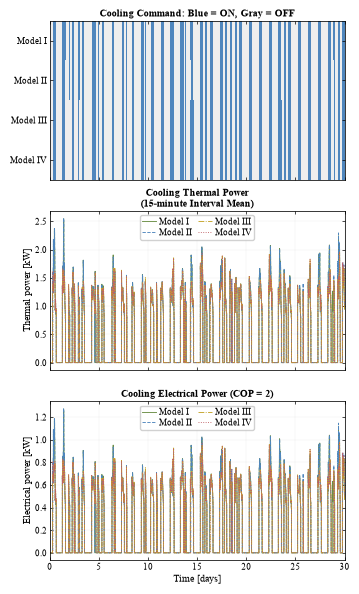

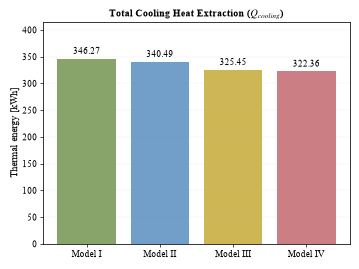

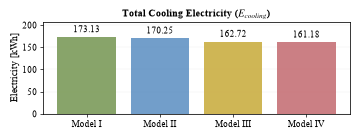

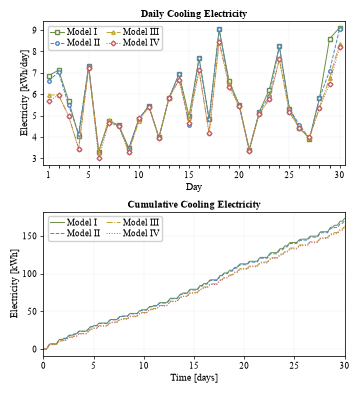

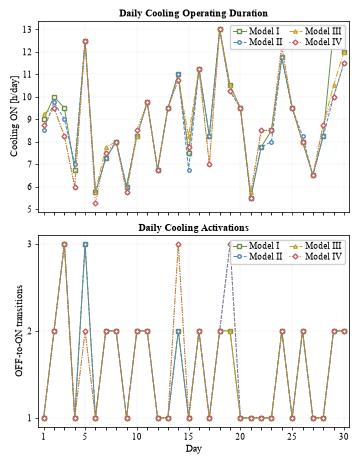

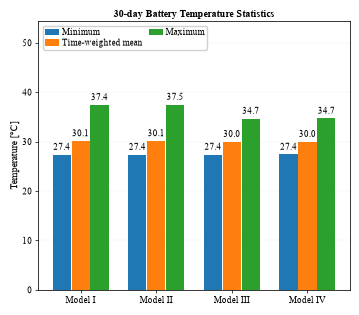

,Thermal_duration_h,Thermal_step_seconds,Cooling_thermal_kWh,Cooling_electric_kWh,Cooling_ON_h,Cooling_activation_cycles,T_min_degC,T_max_degC,T_mean_degC,Daily_electric_min_kWh,Daily_electric_max_kWh,Daily_electric_mean_kWh,Daily_electric_std_kWh,Final_sample_hold_h,COP,Electric_saving_vs_I_kWh,Electric_reduction_vs_I_pct
Model,,,,,,,,,,,,,,,,,
Model I,720,900,346.265,173.133,270.750,47,27.360,37.421,30.107,3.325,9.114,5.771,1.643,0.500,2,0.000,0.000
Model II,720,900,340.492,170.246,265.000,48,27.359,37.492,30.109,3.307,9.059,5.675,1.564,0.500,2,2.886,1.667
Model III,720,900,325.448,162.724,267.500,47,27.377,34.652,29.973,3.276,8.449,5.424,1.415,0.500,2,10.409,6.012
Model IV,720,900,322.360,161.180,264.500,48,27.378,34.666,29.971,3.008,8.458,5.373,1.416,0.500,2,11.952,6.904


Cooling energy covers exactly 720 h; each day has 96 intervals of 15 min.
Results: D:\VScode\30days_scenario_02\runs\scenario02_ef1b5703b8f6\30days_results\assessment\cooling_energy


In [6]:
# COOLING REPORT FROM THE SAME ANALYTICAL THERMAL INTERVALS
from bess_pipeline import export_cooling_report
cooling30_summary, cooling30_daily, cooling30_validation = export_cooling_report(
    ASSESS30_OUTPUT_DIR/'Assessment_30days.xlsx', dpi=600)
display(cooling30_summary.style.format(precision=3))
print('Cooling energy covers exactly 720 h; each day has 96 intervals of 15 min.')
print('Results:', ASSESS30_OUTPUT_DIR/'cooling_energy')


In [56]:
# ORIGINAL AND COPIED REFERENCE FILE INTEGRITY
from bess_pipeline import audit_project
scenario_integrity = audit_project(RUN_ROOT)
print(scenario_integrity)
import json as _scenario_report_json
_scenario_report_path = ASSESS30_OUTPUT_DIR/'cooling_energy'/'Final_report.json'
_scenario_report = _scenario_report_json.loads(_scenario_report_path.read_text(encoding='utf-8'))
_scenario_report['source_integrity'] = scenario_integrity
_scenario_report_path.write_text(_scenario_report_json.dumps(_scenario_report, indent=2)+'\n', encoding='utf-8')
if scenario_integrity['original_audit'].get('original_files_unchanged') is False:
    print('NOTICE: Original workspace differs from its snapshot; recorded in integrity_audit.json. Scenario copy validation remains enforced.')
if not scenario_integrity['copied_reference_files_unchanged']:
    raise RuntimeError('A copied reference file has changed; inspect the audit.')
_scenario_execution = dict(status='SIMULATION_AND_ASSESSMENT_FINISHED', pmp_executed=True,
                           cooling_results_available=True, thermal_duration_h=720.0,
                           thermal_step_seconds=THERMAL_CONFIG.step_seconds)
(RUN_ROOT/'execution_status.json').write_text(_scenario_report_json.dumps(_scenario_execution, indent=2)+'\n', encoding='utf-8')
print('Scenario completed. Configuration, inputs, model results, thermal/cooling reports and validation:', RUN_ROOT)


{'original_audit': {'checked_utc': '2026-11-10T15:33:49.784378+00:00', 'original_root': 'D:\\VScode', 'checked_files': 198, 'original_files_unchanged': False, 'changed_files': [], 'missing_files': ['30days_pairs_results_optimized/Pair_01_20220801_20220802/Model_III_results_2days.xlsx', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Model_II_checkpoint.json', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Model_II_results_2days.xlsx', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Model_IV_results_2days.xlsx', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Model_I_checkpoint.json', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Model_I_results_2days.xlsx', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Pair_assessment.xlsx', '30days_pairs_results_optimized/Pair_01_20220801_20220802/Pair_solver_report.xlsx', '30days_pairs_results_optimized/Pair_02_20220803_20220804/Model_I_checkpoint.json', '30days_pairs_results_optimized/